In [ ]:

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

folder = '/content/drive/MyDrive/Pemesanan 2026'

os.listdir(folder)

['02. Pemesanan Februari 2026.xlsx',
 '03. Pemesanan Maret 2026.xlsx',
 '04. Pemesanan April 2026.xlsx',
 '01. Pemesanan Januari 2026.xlsx',
 '05. Pemesanan Mei 2026.xlsx',
 '06. Pemesanan Juni 2026.xlsx',
 '07. Pemesanan Juli 2026.xlsx',
 'PENUMPANG_KESELURUHAN_JAN_JUL_2026.xlsx']

In [ ]:
# Daftar bulan yang diproses
daftar_bulan = [
    'januari',
    'februari',
    'maret',
    'april',
    'mei',
    'juni',
    'juli'
]

# Daftar stasiun Daop 5
stasiun = [
    'PWT', 'KYA', 'KTA', 'CP', 'KM', 'GB',
    'BMA', 'SLW', 'PPK', 'SDR', 'MA', 'KWN',
    'GM', 'GDM', 'KA', 'SPH', 'JRL', 'KBS'
]

# Kolom yang digunakan
variabel = [
    'TRAIN NAME',
    'DEPART TIME',
    'ORG',
    'DES',
    'TOTAL PSG',
    'REVENUE'
]

In [ ]:
import pandas as pd
for file in os.listdir(folder):

    if file.endswith(('.xlsx', '.xls')):

        file_path = os.path.join(folder, file)

        try:
            excel_file = pd.ExcelFile(file_path)

            print(f'\n📁 File: {file}')
            print('Sheet:', excel_file.sheet_names)

        except Exception as e:
            print(f'❌ Gagal membaca {file}: {e}')


📁 File: 02. Pemesanan Februari 2026.xlsx
Sheet: ['OKUPANSI', 'REV NAIK TRIP DATE', 'Lembar2', 'Lembar1', 'REV TURUN ARRIVAL DATE', 'PEMESANAN DAOP 5', 'PEMESANAN ALL', 'PERBANDINGAN', 'PNP NAIK  TURUN STA', 'VOLUME PENUMPANG NAIK FEBRUARI', 'PENDAPATAN NAIK 2026', 'VOLUME PENUMPANG TURUN']

📁 File: 03. Pemesanan Maret 2026.xlsx
Sheet: ['OKUPANSI', 'REV NAIK TRIP DATE', 'Lembar2', 'Lembar1', 'REV TURUN ARRIVAL DATE', 'PEMESANAN DAOP 5', 'PEMESANAN ALL', 'PERBANDINGAN', 'PNP NAIK  TURUN STA', 'VOLUME PENUMPANG NAIK', 'PENDAPATAN NAIK', 'VOLUME PENUMPANG TURUN ']

📁 File: 04. Pemesanan April 2026.xlsx
Sheet: ['OKUPANSI', 'REV NAIK TRIP DATE', 'Lembar2', 'Lembar1', 'REV TURUN ARRIVAL DATE', 'PEMESANAN DAOP 5', 'PEMESANAN ALL', 'PERBANDINGAN', 'PNP NAIK  TURUN STA', 'PENUMPANG NAIK ', 'PENUMPANG TURUN ', 'PENDAPATAN NAIK DAN VOLUME ']

📁 File: 01. Pemesanan Januari 2026.xlsx
Sheet: ['OKUPANSI', 'REV NAIK TRIP DATE', 'Lembar2', 'Lembar1', 'REV TURUN ARRIVAL DATE', 'PEMESANAN DAOP 5', 'PEMES

In [ ]:
data_semua_bulan = []

for bulan in daftar_bulan:

    # Mencari file berdasarkan nama bulan
    file_ditemukan = [
        file for file in os.listdir(folder)
        if bulan in file.lower()
        and file.endswith(('.xlsx', '.xls'))
    ]

    if not file_ditemukan:
        print(f'⚠️ File {bulan} tidak ditemukan')
        continue

    for file in file_ditemukan:

        file_path = os.path.join(folder, file)

        try:
            # Membaca sheet REV NAIK TRIP DATE
            df = pd.read_excel(
                file_path,
                sheet_name='REV NAIK TRIP DATE'
            )

            # Memastikan kolom tersedia
            kolom_tersedia = [
                kolom for kolom in variabel
                if kolom in df.columns
            ]

            # Memilih kolom yang tersedia
            df_selected = df[kolom_tersedia].copy()

            # Menambahkan kolom bulan
            df_selected['BULAN'] = bulan

            # Menyimpan data
            data_semua_bulan.append(df_selected)

            print(f'✅ {file}: {len(df_selected)} baris')

        except Exception as e:
            print(f'❌ Gagal membaca {file}: {e}')

# Menggabungkan semua bulan
if data_semua_bulan:

    data_gabungan = pd.concat(
        data_semua_bulan,
        ignore_index=True
    )

    print('\nTotal data:', len(data_gabungan))

    # Ringkasan jumlah data setiap bulan
    print('\nJumlah data setiap bulan:')
    display(data_gabungan['BULAN'].value_counts())

    # Menampilkan 20 baris pertama
    display(data_gabungan.head(20))

else:
    print('Tidak ada data yang berhasil dibaca.')

✅ 01. Pemesanan Januari 2026.xlsx: 64258 baris
✅ 02. Pemesanan Februari 2026.xlsx: 54652 baris
✅ 03. Pemesanan Maret 2026.xlsx: 80674 baris
✅ 04. Pemesanan April 2026.xlsx: 64377 baris
✅ 05. Pemesanan Mei 2026.xlsx: 66879 baris
✅ 06. Pemesanan Juni 2026.xlsx: 69509 baris
✅ 07. Pemesanan Juli 2026.xlsx: 67493 baris

Total data: 467842

Jumlah data setiap bulan:


,count
BULAN,
maret,80674
juni,69509
juli,67493
mei,66879
april,64377
januari,64258
februari,54652


,BULAN
0,januari
1,januari
2,januari
3,januari
4,januari
5,januari
6,januari
7,januari
8,januari
9,januari


In [ ]:
for kolom in data_gabungan.columns:
    print(repr(kolom))

'BULAN'


In [ ]:
df = pd.read_excel(
    file_path,
    sheet_name='REV NAIK TRIP DATE'
)

In [ ]:
# Membaca Excel tanpa header terlebih dahulu
df_raw = pd.read_excel(
    file_path,
    sheet_name='REV NAIK TRIP DATE',
    header=None
)

# Mencari baris yang berisi TRAIN NAME
baris_header = None

for i, row in df_raw.iterrows():
    if row.astype(str).str.contains(
        'TRAIN NAME',
        case=False,
        na=False
    ).any():
        baris_header = i
        break

if baris_header is None:
    raise ValueError('Header TRAIN NAME tidak ditemukan')

# Membaca ulang dengan header yang benar
df = pd.read_excel(
    file_path,
    sheet_name='REV NAIK TRIP DATE',
    header=baris_header
)

# Membersihkan nama kolom
df.columns = (
    df.columns.astype(str)
    .str.replace('\xa0', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.upper()
)

print(df.columns.tolist())

['TRAIN NUMBER', 'TRAIN NAME', 'DEPART TIME', 'ARRIVAL TIME', 'BUSINESS AREA', 'ORG', 'DES', 'CLASS', 'CAPACITY', 'WAGON', 'TOTAL PSG', 'PSG KM', 'OCCUPANCY', 'REVENUE', 'POINT REVENUE', 'NETT REVENUE']


In [ ]:
import pandas as pd
import os

for bulan in daftar_bulan:

    file_ditemukan = [
        file for file in os.listdir(folder)
        if bulan in file.lower()
        and file.endswith(('.xlsx', '.xls'))
    ]

    if not file_ditemukan:
        print(f'⚠️ File {bulan} tidak ditemukan')
        continue

    for file in file_ditemukan:

        file_path = os.path.join(folder, file)

        # Membaca tanpa header
        df_raw = pd.read_excel(
            file_path,
            sheet_name='REV NAIK TRIP DATE',
            header=None
        )

        # Mencari baris header
        baris_header = None

        for i, row in df_raw.iterrows():
            if row.astype(str).str.contains(
                'TRAIN NAME',
                case=False,
                na=False
            ).any():
                baris_header = i
                break

        if baris_header is None:
            print(f'❌ Header tidak ditemukan: {file}')
            continue

        # Membaca dengan header yang benar
        df = pd.read_excel(
            file_path,
            sheet_name='REV NAIK TRIP DATE',
            header=baris_header
        )

        # Membersihkan nama kolom
        df.columns = (
            df.columns.astype(str)
            .str.replace('\xa0', ' ', regex=False)
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip()
            .str.upper()
        )

        print(f'\n{"="*60}')
        print(f'📁 DATA BULAN: {bulan.upper()}')
        print(f'📄 FILE: {file}')
        print(f'Jumlah baris: {len(df)}')
        print(f'Jumlah kolom: {len(df.columns)}')
        print(f'{"="*60}')

        # Menampilkan seluruh data
        display(df)


📁 DATA BULAN: JANUARI
📄 FILE: 01. Pemesanan Januari 2026.xlsx
Jumlah baris: 64252
Jumlah kolom: 16


,TRAIN NUMBER,TRAIN NAME,DEPART TIME,ARRIVAL TIME,BUSINESS AREA,ORG,DES,CLASS,CAPACITY,WAGON,TOTAL PSG,PSG KM,OCCUPANCY,REVENUE,POINT REVENUE,NETT REVENUE
0,7002A,GAJAYANA TAMBAHAN,2026-01-01 00:00:00,2026-01-01 13:50:00,DAOP 5 PURWOKERTO,PWT,BL,EKS,399.0,8.0,1.0,484.610,0.00,625000.0,12000.0,613000.0
1,7002A,GAJAYANA TAMBAHAN,2026-01-01 00:00:00,2026-01-01 13:50:00,DAOP 5 PURWOKERTO,PWT,YK,EKS,399.0,8.0,6.0,1001.310,0.01,1650000.0,6000.0,1644000.0
2,7002A,GAJAYANA TAMBAHAN,2026-01-01 00:00:00,2026-01-01 13:50:00,DAOP 5 PURWOKERTO,KYA,SLO,EKS,399.0,8.0,1.0,198.955,0.00,470000.0,9000.0,461000.0
3,7025,KA TAMBAHAN SLO PSE,2026-01-01 00:00:00,2026-01-01 12:27:00,DAOP 5 PURWOKERTO,KA,BKS,EKO,576.0,8.0,3.0,1160.244,0.00,945000.0,0.0,945000.0
4,7025,KA TAMBAHAN SLO PSE,2026-01-01 00:00:00,2026-01-01 12:27:00,DAOP 5 PURWOKERTO,PWT,CN,EKO,576.0,8.0,1.0,130.787,0.00,238000.0,4000.0,234000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64247,DAOP 5 PURWOKERTO,94.818,0,287.677,28066522000,0,38625672308,96629696.812,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64248,TOTAL,94.818,0,287.677,28066522000,0,38625672308,96629696.812,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64249,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64250,GRANDTOTALPSG,GRANDTOTALREVENUE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



📁 DATA BULAN: FEBRUARI
📄 FILE: 02. Pemesanan Februari 2026.xlsx
Jumlah baris: 54646
Jumlah kolom: 16


,TRAIN NUMBER,TRAIN NAME,DEPART TIME,ARRIVAL TIME,BUSINESS AREA,ORG,DES,CLASS,CAPACITY,WAGON,TOTAL PSG,PSG KM,OCCUPANCY,REVENUE,POINT REVENUE,NETT REVENUE
0,7002A,GAJAYANA TAMBAHAN,2026-02-01,2026-02-01 13:50:00,DAOP 5 PURWOKERTO,KM,PPR,EKS,400,8,2,660.084,0.00,880000,0,880000
1,7002A,GAJAYANA TAMBAHAN,2026-02-01,2026-02-01 13:50:00,DAOP 5 PURWOKERTO,PWT,YK,EKS,400,8,4,667.540,0.01,1672000,16000,1656000
2,275B,PASUNDAN,2026-02-01,2026-02-01 18:58:00,DAOP 5 PURWOKERTO,MA,KAC,EKO,504,7,4,919.824,0.00,936000,0,936000
3,275B,PASUNDAN,2026-02-01,2026-02-01 18:58:00,DAOP 5 PURWOKERTO,KYA,CI,EKO,504,7,1,114.080,0.00,70000,0,70000
4,275B,PASUNDAN,2026-02-01,2026-02-01 18:58:00,DAOP 5 PURWOKERTO,KM,BJR,EKO,504,7,3,419.298,0.00,468000,0,468000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54641,255B,JAKA TINGKIR,2026-02-28,2026-03-01 07:44:00,DAOP 5 PURWOKERTO,PWT,PSE,EKO,576,8,5,1719.050,0.00,1500000,12000,1488000
54642,255B,JAKA TINGKIR,2026-02-28,2026-03-01 07:44:00,DAOP 5 PURWOKERTO,KM,CKR,EKO,576,8,1,381.792,0.00,400000,0,400000
54643,255B,JAKA TINGKIR,2026-02-28,2026-03-01 07:44:00,DAOP 5 PURWOKERTO,KWN,CNP,EKO,576,8,2,426.596,0.00,600000,6000,594000
54644,255B,JAKA TINGKIR,2026-02-28,2026-03-01 07:44:00,DAOP 5 PURWOKERTO,KYA,PSE,EKO,576,8,1,370.977,0.00,400000,8000,392000



📁 DATA BULAN: MARET
📄 FILE: 03. Pemesanan Maret 2026.xlsx
Jumlah baris: 80668
Jumlah kolom: 16


...

,TRAIN NUMBER,TRAIN NAME,DEPART TIME,ARRIVAL TIME,BUSINESS AREA,ORG,DES,CLASS,CAPACITY,WAGON,TOTAL PSG,PSG KM,OCCUPANCY,REVENUE,POINT REVENUE,NETT REVENUE
0,275B,PASUNDAN,2026-05-01,2026-05-01 18:58:00,DAOP 5 PURWOKERTO,MA,KAC,EKO,504,7,1,229.956,0.0,250000,0,250000
1,275B,PASUNDAN,2026-05-01,2026-05-01 18:58:00,DAOP 5 PURWOKERTO,GB,SDR,EKO,504,7,1,84.620,0.0,250000,0,250000
2,275B,PASUNDAN,2026-05-01,2026-05-01 18:58:00,DAOP 5 PURWOKERTO,KYA,TSM,EKO,504,7,5,662.915,0.0,350000,0,350000
3,275B,PASUNDAN,2026-05-01,2026-05-01 18:58:00,DAOP 5 PURWOKERTO,GB,KAC,EKO,504,7,2,542.286,0.0,500000,0,500000
4,275B,PASUNDAN,2026-05-01,2026-05-01 18:58:00,DAOP 5 PURWOKERTO,MA,TSM,EKO,504,7,1,119.885,0.0,70000,0,70000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66868,255B,JAKA TINGKIR,2026-05-31,2026-06-01 07:44:00,DAOP 5 PURWOKERTO,GB,CKR,EKO,576,8,1,362.322,0.0,400000,0,400000
66869,255B,JAKA TINGKIR,2026-05-31,2026-06-01 07:44:00,DAOP 5 PURWOKERTO,KWN,CKR,EKO,576,8,1,390.782,0.0,450000,0,450000
66870,255B,JAKA TINGKIR,2026-05-31,2026-06-01 07:44:00,DAOP 5 PURWOKERTO,KM,CKR,EKO,576,8,5,1908.960,0.0,1650000,0,1650000
66871,255B,JAKA TINGKIR,2026-05-31,2026-06-01 07:44:00,DAOP 5 PURWOKERTO,KTA,PSE,EKO,576,8,3,1341.138,0.0,1300000,0,1300000



📁 DATA BULAN: JUNI
📄 FILE: 06. Pemesanan Juni 2026.xlsx
Jumlah baris: 69503
Jumlah kolom: 16


,TRAIN NUMBER,TRAIN NAME,DEPART TIME,ARRIVAL TIME,BUSINESS AREA,ORG,DES,CLASS,CAPACITY,WAGON,TOTAL PSG,PSG KM,OCCUPANCY,REVENUE,POINT REVENUE,NETT REVENUE
0,275B,PASUNDAN,2026-06-01,2026-06-01 18:58:00,DAOP 5 PURWOKERTO,MA,KAC,EKO,504,7,13,2989.428,0.02,3385000,0,3385000
1,275B,PASUNDAN,2026-06-01,2026-06-01 18:58:00,DAOP 5 PURWOKERTO,KYA,KAC,EKO,504,7,18,4367.772,0.03,4581000,0,4581000
2,275B,PASUNDAN,2026-06-01,2026-06-01 18:58:00,DAOP 5 PURWOKERTO,KYA,RCK,EKO,504,7,4,919.204,0.00,1060000,0,1060000
3,275B,PASUNDAN,2026-06-01,2026-06-01 18:58:00,DAOP 5 PURWOKERTO,KTA,CB,EKO,504,7,10,2652.160,0.01,2534000,0,2534000
4,275B,PASUNDAN,2026-06-01,2026-06-01 18:58:00,DAOP 5 PURWOKERTO,KM,KAC,EKO,504,7,14,4068.582,0.02,3710000,0,3710000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69498,255B,JAKA TINGKIR,2026-06-30,2026-07-01 07:44:00,DAOP 5 PURWOKERTO,KTA,CKR,EKO,576,8,5,2049.510,0.00,1400000,0,1400000
69499,255B,JAKA TINGKIR,2026-06-30,2026-07-01 07:44:00,DAOP 5 PURWOKERTO,KTA,JNG,EKO,576,8,1,441.441,0.00,280000,0,280000
69500,255B,JAKA TINGKIR,2026-06-30,2026-07-01 07:44:00,DAOP 5 PURWOKERTO,KYA,CKR,EKO,576,8,5,1669.165,0.00,915000,0,915000
69501,255B,JAKA TINGKIR,2026-06-30,2026-07-01 07:44:00,DAOP 5 PURWOKERTO,KTA,PSE,EKO,576,8,4,1788.184,0.00,1120000,0,1120000



📁 DATA BULAN: JULI
📄 FILE: 07. Pemesanan Juli 2026.xlsx
Jumlah baris: 67487
Jumlah kolom: 16


,TRAIN NUMBER,TRAIN NAME,DEPART TIME,ARRIVAL TIME,BUSINESS AREA,ORG,DES,CLASS,CAPACITY,WAGON,TOTAL PSG,PSG KM,OCCUPANCY,REVENUE,POINT REVENUE,NETT REVENUE
0,275B,PASUNDAN,2026-07-01,2026-07-01 18:58:00,DAOP 5 PURWOKERTO,KM,LL,EKO,504,7,1,247.779,0.00,185000,0,185000
1,275B,PASUNDAN,2026-07-01,2026-07-01 18:58:00,DAOP 5 PURWOKERTO,KM,KAC,EKO,504,7,13,3777.969,0.02,2405000,0,2405000
2,275B,PASUNDAN,2026-07-01,2026-07-01 18:58:00,DAOP 5 PURWOKERTO,MA,TSM,EKO,504,7,2,239.770,0.00,370000,0,370000
3,275B,PASUNDAN,2026-07-01,2026-07-01 18:58:00,DAOP 5 PURWOKERTO,MA,BJR,EKO,504,7,2,158.218,0.00,370000,0,370000
4,275B,PASUNDAN,2026-07-01,2026-07-01 18:58:00,DAOP 5 PURWOKERTO,SDR,TSM,EKO,504,7,1,76.452,0.00,70000,0,70000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67482,255B,JAKA TINGKIR,2026-07-31,2026-08-01 07:44:00,DAOP 5 PURWOKERTO,KYA,JNG,EKO,576,8,1,365.372,0.00,450000,0,450000
67483,255B,JAKA TINGKIR,2026-07-31,2026-08-01 07:44:00,DAOP 5 PURWOKERTO,KYA,PWT,EKO,576,8,1,27.167,0.00,105000,0,105000
67484,255B,JAKA TINGKIR,2026-07-31,2026-08-01 07:44:00,DAOP 5 PURWOKERTO,KYA,PSE,EKO,576,8,4,1483.908,0.00,1800000,0,1800000
67485,255B,JAKA TINGKIR,2026-07-31,2026-08-01 07:44:00,DAOP 5 PURWOKERTO,KTA,CKR,EKO,576,8,5,2049.510,0.00,1850000,0,1850000


In [ ]:
ringkasan_missing = []

for bulan in daftar_bulan:

    file_ditemukan = [
        file for file in os.listdir(folder)
        if bulan in file.lower()
        and file.endswith(('.xlsx', '.xls'))
    ]

    for file in file_ditemukan:

        file_path = os.path.join(folder, file)

        df_raw = pd.read_excel(
            file_path,
            sheet_name='REV NAIK TRIP DATE',
            header=None
        )

        baris_header = None

        for i, row in df_raw.iterrows():
            if row.astype(str).str.contains(
                'TRAIN NAME',
                case=False,
                na=False
            ).any():
                baris_header = i
                break

        df = pd.read_excel(
            file_path,
            sheet_name='REV NAIK TRIP DATE',
            header=baris_header
        )

        df.columns = (
            df.columns.astype(str)
            .str.replace('\xa0', ' ', regex=False)
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip()
            .str.upper()
        )

        for kolom in variabel:
            jumlah_missing = df[kolom].isnull().sum()

            ringkasan_missing.append({
                'Bulan': bulan.upper(),
                'Kolom': kolom,
                'Jumlah Missing': jumlah_missing,
                'Persentase (%)': round(
                    jumlah_missing / len(df) * 100, 2
                )
            })

tabel_missing_semua = pd.DataFrame(ringkasan_missing)

display(tabel_missing_semua)

,Bulan,Kolom,Jumlah Missing,Persentase (%)
0,JANUARI,TRAIN NAME,3,0.00
1,JANUARI,DEPART TIME,5,0.01
2,JANUARI,ORG,5,0.01
3,JANUARI,DES,5,0.01
4,JANUARI,TOTAL PSG,8,0.01
5,JANUARI,REVENUE,8,0.01
6,FEBRUARI,TRAIN NAME,0,0.00
7,FEBRUARI,DEPART TIME,0,0.00
8,FEBRUARI,ORG,0,0.00
9,FEBRUARI,DES,0,0.00


In [ ]:
# Membaca data Januari
file_januari = [
    file for file in os.listdir(folder)
    if 'januari' in file.lower()
    and file.endswith(('.xlsx', '.xls'))
][0]

path_januari = os.path.join(folder, file_januari)

df_raw = pd.read_excel(
    path_januari,
    sheet_name='REV NAIK TRIP DATE',
    header=None
)

# Mencari baris header
for i, row in df_raw.iterrows():
    if row.astype(str).str.contains(
        'TRAIN NAME',
        case=False,
        na=False
    ).any():
        baris_header = i
        break

data_januari = pd.read_excel(
    path_januari,
    sheet_name='REV NAIK TRIP DATE',
    header=baris_header
)

data_januari.columns = (
    data_januari.columns.astype(str)
    .str.replace('\xa0', ' ', regex=False)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
    .str.upper()
)

# Menampilkan baris yang memiliki missing value
data_januari_missing = data_januari[
    data_januari[variabel].isnull().any(axis=1)
]

display(data_januari_missing)

,TRAIN NUMBER,TRAIN NAME,DEPART TIME,ARRIVAL TIME,BUSINESS AREA,ORG,DES,CLASS,CAPACITY,WAGON,TOTAL PSG,PSG KM,OCCUPANCY,REVENUE,POINT REVENUE,NETT REVENUE
64244,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64245,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64246,BUSINESS AREA,PSG EKS,PSG BIS,PSG EKO,REVENUE EKS,REVENUE BIS,REVENUE EKO,PSG DISTANCE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64247,DAOP 5 PURWOKERTO,94.818,0,287.677,28066522000,0,38625672308,96629696.812,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64248,TOTAL,94.818,0,287.677,28066522000,0,38625672308,96629696.812,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64249,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64250,GRANDTOTALPSG,GRANDTOTALREVENUE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64251,382495,66692194308,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Menghapus baris yang tidak memiliki nama kereta
data_januari_bersih = data_januari.dropna(
    subset=['TRAIN NAME']
).copy()

# Menghapus baris yang TOTAL PSG-nya kosong
data_januari_bersih = data_januari_bersih.dropna(
    subset=['TOTAL PSG']
).copy()

# Mengecek missing value
display(data_januari_bersih[variabel].isnull().sum())

In [ ]:
import pandas as pd
import os

ringkasan_missing = []

for bulan in daftar_bulan:

    file_ditemukan = [
        file for file in os.listdir(folder)
        if bulan in file.lower()
        and file.endswith(('.xlsx', '.xls'))
    ]

    for file in file_ditemukan:

        file_path = os.path.join(folder, file)

        # Membaca tanpa header
        df_raw = pd.read_excel(
            file_path,
            sheet_name='REV NAIK TRIP DATE',
            header=None
        )

        # Mencari header TRAIN NAME
        baris_header = None

        for i, row in df_raw.iterrows():
            if row.astype(str).str.contains(
                'TRAIN NAME',
                case=False,
                na=False
            ).any():
                baris_header = i
                break

        if baris_header is None:
            print(f'❌ Header tidak ditemukan: {file}')
            continue

        # Membaca dengan header yang benar
        df = pd.read_excel(
            file_path,
            sheet_name='REV NAIK TRIP DATE',
            header=baris_header
        )

        # Membersihkan nama kolom
        df.columns = (
            df.columns.astype(str)
            .str.replace('\xa0', ' ', regex=False)
            .str.replace(r'\s+', ' ', regex=True)
            .str.strip()
            .str.upper()
        )

        # Memilih variabel
        df = df[variabel].copy()

        # Menghapus baris ringkasan dan baris kosong
        df = df.dropna(
            subset=['TRAIN NAME', 'TOTAL PSG']
        ).copy()

        # Menghitung missing value setelah pembersihan
        for kolom in variabel:

            jumlah_missing = df[kolom].isnull().sum()

            ringkasan_missing.append({
                'Bulan': bulan.upper(),
                'Kolom': kolom,
                'Jumlah Missing': jumlah_missing,
                'Persentase (%)': round(
                    jumlah_missing / len(df) * 100, 2
                )
            })

# Membuat tabel hasil
tabel_missing_semua = pd.DataFrame(
    ringkasan_missing
)

display(tabel_missing_semua)

,Bulan,Kolom,Jumlah Missing,Persentase (%)
0,JANUARI,TRAIN NAME,0,0.0
1,JANUARI,DEPART TIME,0,0.0
2,JANUARI,ORG,0,0.0
3,JANUARI,DES,0,0.0
4,JANUARI,TOTAL PSG,0,0.0
5,JANUARI,REVENUE,0,0.0
6,FEBRUARI,TRAIN NAME,0,0.0
7,FEBRUARI,DEPART TIME,0,0.0
8,FEBRUARI,ORG,0,0.0
9,FEBRUARI,DES,0,0.0


In [ ]:

import pandas as pd
import os
import glob

# ==========================================
# 1. LOKASI FOLDER
# ==========================================
folder = '/content/drive/MyDrive/Pemesanan 2026'

daftar_bulan = [
    'januari', 'februari', 'maret', 'april',
    'mei', 'juni', 'juli'
]

data_gabungan = []

# ==========================================
# 2. BACA DAN GABUNGKAN FILE JANUARI-JULI
# ==========================================
for bulan in daftar_bulan:

    file_bulan = [
        f for f in glob.glob(os.path.join(folder, '*.xlsx'))
        if bulan in os.path.basename(f).lower()
        and not os.path.basename(f).startswith('~$')
        and 'PENUMPANG_KESELURUHAN' not in os.path.basename(f).upper()
    ]

    if len(file_bulan) != 1:
        print(
            f'{bulan.upper()}: ditemukan {len(file_bulan)} file. '
            'Periksa nama file sebelum melanjutkan.'
        )
        continue

    file_path = file_bulan[0]

    # Baca nama sheet
    excel = pd.ExcelFile(file_path)

    sheet = next(
        (
            s for s in excel.sheet_names
            if s.strip().upper() == 'REV NAIK TRIP DATE'
        ),
        None
    )

    if sheet is None:
        print(f'Sheet REV NAIK TRIP DATE tidak ditemukan: {bulan}')
        continue

    # Cari baris header
    preview = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None,
        nrows=15
    )

    header_row = None

    for i in range(len(preview)):
        baris = preview.iloc[i].astype(str).str.strip().str.upper()

        if 'TRAIN NAME' in baris.values and 'DEPART TIME' in baris.values:
            header_row = i
            break

    if header_row is None:
        print(f'Header tidak ditemukan: {bulan}')
        continue

    # Baca data dengan header yang ditemukan
    df = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=header_row
    )

    # Rapikan nama kolom
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.upper()
        .str.replace(r'\s+', ' ', regex=True)
    )

    # Tambahkan nama bulan asal sebagai penanda
    df['BULAN'] = bulan.capitalize()

    # Gabungkan ke daftar data
    data_gabungan.append(df)

    print(f'{bulan.capitalize()}: {len(df)} baris berhasil dibaca.')

# ==========================================
# 3. GABUNGKAN SELURUH DATA
# ==========================================
if len(data_gabungan) == 0:
    raise ValueError(
        'Tidak ada data yang berhasil dibaca. '
        'Periksa folder, nama file, dan nama sheet.'
    )

penumpang_keseluruhan = pd.concat(
    data_gabungan,
    ignore_index=True,
    sort=False
)

# ==========================================
# 4. SIMPAN MENJADI SATU FILE EXCEL
# ==========================================
file_output = os.path.join(
    folder,
    'PENUMPANG_KESELURUHAN_JAN_JUL_2026.xlsx'
)

penumpang_keseluruhan.to_excel(
    file_output,
    sheet_name='PENUMPANG KESELURUHAN',
    index=False
)

# ==========================================
# 5. CEK HASIL
# ==========================================
print('\nJUMLAH BARIS PER BULAN:')
print(penumpang_keseluruhan['BULAN'].value_counts())

print('\nTOTAL BARIS:', len(penumpang_keseluruhan))
print('\nFILE BERHASIL DISIMPAN DI:')
print(file_output)


In [ ]:
from IPython.display import display

display(penumpang_keseluruhan.head(20))

In [ ]:
print(penumpang_keseluruhan.columns.tolist())

['TRAIN NUMBER', 'TRAIN NAME', 'DEPART TIME', 'ARRIVAL TIME', 'BUSINESS AREA', 'ORG', 'DES', 'CLASS', 'CAPACITY', 'WAGON', 'TOTAL PSG', 'PSG KM', 'OCCUPANCY', 'REVENUE', 'POINT REVENUE', 'NETT REVENUE', 'BULAN']


In [ ]:

import pandas as pd

# ==========================================
# 1. PASTIKAN DEPART TIME BERUPA DATETIME
# ==========================================
penumpang_keseluruhan['DEPART TIME'] = pd.to_datetime(
    penumpang_keseluruhan['DEPART TIME'],
    errors='coerce'
)

# ==========================================
# 2. BUAT KOLOM TANGGAL (1-31)
# ==========================================
penumpang_keseluruhan['TANGGAL'] = (
    penumpang_keseluruhan['DEPART TIME'].dt.day
)

# ==========================================
# 3. BUAT KOLOM NAMA HARI
# ==========================================
nama_hari = {
    'Monday': 'Senin',
    'Tuesday': 'Selasa',
    'Wednesday': 'Rabu',
    'Thursday': 'Kamis',
    'Friday': 'Jumat',
    'Saturday': 'Sabtu',
    'Sunday': 'Minggu'
}

penumpang_keseluruhan['Day Name'] = (
    penumpang_keseluruhan['DEPART TIME']
    .dt.day_name()
    .map(nama_hari)
)

# ==========================================
# 4. KALENDER LIBUR RESMI SESUAI DAFTARMU
# ==========================================
kalender_libur = {
    "2026-01-01": ("Tahun Baru Masehi", "Libur Nasional"),
    "2026-01-16": ("Isra Mikraj Nabi Muhammad SAW", "Libur Nasional"),
    "2026-02-16": ("Cuti Bersama Tahun Baru Imlek", "Cuti Bersama"),
    "2026-02-17": ("Tahun Baru Imlek 2577 Kongzili", "Libur Nasional"),
    "2026-03-18": ("Cuti Bersama Hari Suci Nyepi", "Cuti Bersama"),
    "2026-03-19": ("Hari Suci Nyepi", "Libur Nasional"),
    "2026-03-20": ("Cuti Bersama Idulfitri", "Cuti Bersama"),
    "2026-03-21": ("Hari Raya Idulfitri", "Libur Nasional"),
    "2026-03-22": ("Hari Raya Idulfitri", "Libur Nasional"),
    "2026-03-23": ("Cuti Bersama Idulfitri", "Cuti Bersama"),
    "2026-03-24": ("Cuti Bersama Idulfitri", "Cuti Bersama"),
    "2026-04-03": ("Wafat Yesus Kristus", "Libur Nasional"),
    "2026-04-05": ("Kebangkitan Yesus Kristus", "Libur Nasional"),
    "2026-05-01": ("Hari Buruh Internasional", "Libur Nasional"),
    "2026-05-14": ("Kenaikan Yesus Kristus", "Libur Nasional"),
    "2026-05-15": ("Cuti Bersama Kenaikan Yesus Kristus", "Cuti Bersama"),
    "2026-05-27": ("Hari Raya Iduladha", "Libur Nasional"),
    "2026-05-28": ("Cuti Bersama Iduladha", "Cuti Bersama"),
    "2026-05-31": ("Hari Raya Waisak", "Libur Nasional"),
    "2026-06-01": ("Hari Lahir Pancasila", "Libur Nasional"),
    "2026-06-16": ("Tahun Baru Islam 1448 H", "Libur Nasional")
}

# ==========================================
# 5. KATEGORI HARI LIBUR
# ==========================================
tanggal_libur = {
    pd.Timestamp(tanggal): (keterangan, kategori)
    for tanggal, (keterangan, kategori) in kalender_libur.items()
}

# Gunakan tanggal lengkap untuk mencocokkan kalender
tanggal_lengkap = (
    penumpang_keseluruhan['DEPART TIME'].dt.normalize()
)

penumpang_keseluruhan['Hari libur'] = tanggal_lengkap.map(
    lambda t: tanggal_libur[t][1]
    if pd.notna(t) and t in tanggal_libur
    else 'Bukan Libur'
)

# ==========================================
# 6. SIMPAN KETERANGAN NAMA LIBUR
# ==========================================
penumpang_keseluruhan['Keterangan Libur'] = tanggal_lengkap.map(
    lambda t: tanggal_libur[t][0]
    if pd.notna(t) and t in tanggal_libur
    else None
)

# ==========================================
# 7. SIMPAN FILE EXCEL
# ==========================================
file_output = (
    '/content/drive/MyDrive/Pemesanan 2026/'
    'PENUMPANG_KESELURUHAN_JAN_JUL_2026.xlsx'
)

penumpang_keseluruhan.to_excel(
    file_output,
    sheet_name='PENUMPANG KESELURUHAN',
    index=False
)

# ==========================================
# 8. TAMPILKAN HASIL
# ==========================================
display(
    penumpang_keseluruhan[
        [
            'DEPART TIME',
            'TANGGAL',
            'Day Name',
            'Hari libur',
            'Keterangan Libur'
        ]
    ].head(20)
)

print('\nJumlah data per kategori:')
display(
    penumpang_keseluruhan['Hari libur']
    .value_counts()
    .rename_axis('Kategori')
    .reset_index(name='Jumlah Baris')
)

print('\nFile berhasil diperbarui:')
print(file_output)


In [ ]:
print(penumpang_keseluruhan.shape)

display(
    penumpang_keseluruhan[
        ["DEPART TIME", "ORG", "DES", "TOTAL PSG"]
    ].head()
)

(467800, 21)


,DEPART TIME,ORG,DES,TOTAL PSG
0,2026-01-01,PWT,BL,1.0
1,2026-01-01,PWT,YK,6.0
2,2026-01-01,KYA,SLO,1.0
3,2026-01-01,KA,BKS,3.0
4,2026-01-01,PWT,CN,1.0


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. SALIN DATA DAN FILTER PERIODE
# ==========================================
df = penumpang_keseluruhan.copy()

df["DEPART TIME"] = pd.to_datetime(
    df["DEPART TIME"], errors="coerce"
)
df["TOTAL PSG"] = pd.to_numeric(
    df["TOTAL PSG"], errors="coerce"
)

# Hapus tanggal kosong
df = df.dropna(subset=["DEPART TIME"]).copy()

# Buat tanggal tanpa jam
df["Tanggal_Lengkap"] = df["DEPART TIME"].dt.normalize()

# Hanya gunakan periode Januari–Juli 2026
df = df[
    (df["Tanggal_Lengkap"] >= "2026-01-01") &
    (df["Tanggal_Lengkap"] < "2026-08-01")
].copy()

# Tangani nilai penumpang kosong
df["TOTAL PSG"] = df["TOTAL PSG"].fillna(0)

# Rapikan kategori hari libur
df["Hari libur"] = (
    df["Hari libur"]
    .fillna("Bukan Libur")
    .astype(str)
    .str.strip()
)

# ==========================================
# 2. AGREGASI TOTAL PENUMPANG PER TANGGAL
# ==========================================
harian = (
    df.groupby("Tanggal_Lengkap", as_index=False)
    .agg(
        Total_Penumpang=("TOTAL PSG", "sum"),
        Kategori_Libur=("Hari libur", "first")
    )
)

harian["Bulan"] = harian["Tanggal_Lengkap"].dt.to_period("M")

harian["Kelompok_Hari"] = np.where(
    harian["Kategori_Libur"].str.lower().eq("bukan libur"),
    "Hari Biasa",
    "Hari Libur"
)

# ==========================================
# 3. RATA-RATA BERDASARKAN KATEGORI LIBUR
# ==========================================
rata_libur = (
    harian.groupby("Kategori_Libur")["Total_Penumpang"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
bars = plt.bar(rata_libur.index, rata_libur.values)

plt.title("Rata-rata Penumpang Harian Berdasarkan Kategori Hari")
plt.xlabel("Kategori Hari")
plt.ylabel("Rata-rata Penumpang per Hari")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar, nilai in zip(bars, rata_libur.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{nilai:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# ==========================================
# 4. RATA-RATA BULANAN: HARI BIASA VS LIBUR
# ==========================================
bulanan_libur = (
    harian.groupby(["Bulan", "Kelompok_Hari"])["Total_Penumpang"]
    .mean()
    .unstack()
    .sort_index()
)

nama_bulan = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "Mei", 6: "Jun", 7: "Jul", 8: "Agu",
    9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"
}

label_bulan = [
    f"{nama_bulan[b.month]} {b.year}"
    for b in bulanan_libur.index
]

plt.figure(figsize=(11, 5))

for kategori in ["Hari Biasa", "Hari Libur"]:
    if kategori in bulanan_libur.columns:
        plt.plot(
            label_bulan,
            bulanan_libur[kategori],
            marker="o",
            linewidth=2,
            label=kategori
        )

plt.title("Rata-rata Penumpang Harian per Bulan: Hari Biasa vs Hari Libur")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata Penumpang per Hari")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend(title="Kategori")
plt.tight_layout()
plt.show()

# ==========================================
# 5. VALIDASI DATA
# ==========================================
print("Rentang tanggal:", harian["Tanggal_Lengkap"].min(),
      "sampai", harian["Tanggal_Lengkap"].max())

print("\nJumlah tanggal unik per bulan:")
display(
    harian.groupby("Bulan")["Tanggal_Lengkap"]
    .nunique()
    .rename("Jumlah Tanggal")
    .reset_index()
)

print("\nRata-rata penumpang bulanan:")
display(bulanan_libur.round(0))


jumlah penumpang setiap stasiun untuk masing-masing bulan Januari–Juli 2026.


In [ ]:

import pandas as pd

# Pastikan tipe data benar
df = penumpang_keseluruhan.copy()
df["DEPART TIME"] = pd.to_datetime(df["DEPART TIME"], errors="coerce")
df["TOTAL PSG"] = pd.to_numeric(df["TOTAL PSG"], errors="coerce")

# Nama bulan dalam urutan kalender
nama_bulan = {
    1: "Januari", 2: "Februari", 3: "Maret",
    4: "April", 5: "Mei", 6: "Juni", 7: "Juli"
}

df["BULAN_KE"] = df["DEPART TIME"].dt.month

# Total penumpang per stasiun asal dan bulan
permintaan_stasiun = (
    df.dropna(subset=["ORG", "DEPART TIME", "TOTAL PSG"])
      .groupby(["ORG", "BULAN_KE"])["TOTAL PSG"]
      .sum()
      .unstack(fill_value=0)
      .reindex(columns=range(1, 8), fill_value=0)
)

permintaan_stasiun.columns = [
    nama_bulan[i] for i in range(1, 8)
]

display(permintaan_stasiun)
print("Jumlah stasiun:", len(permintaan_stasiun))


TABEL FLUKTUASI PENUMPANG BULANAN


,Total Penumpang,Perubahan Penumpang,Perubahan (%),Arah Perubahan
Januari,381613.0,NaN,NaN,Awal periode
Februari,298402.0,-83211.0,-21.81,Turun
Maret,524911.0,226509.0,75.91,Naik
April,396732.0,-128179.0,-24.42,Turun
Mei,403128.0,6396.0,1.61,Naik
Juni,451789.0,48661.0,12.07,Naik
Juli,412304.0,-39485.0,-8.74,Turun



RINGKASAN FLUKTUASI DAN KONSISTENSI
Rata-rata penumpang per bulan : 409,839.86
Simpangan baku bulanan        : 68,846.67
Koefisien variasi (CV)        : 16.80%
Bulan dengan penumpang tertinggi: Maret
Bulan dengan penumpang terendah : Februari


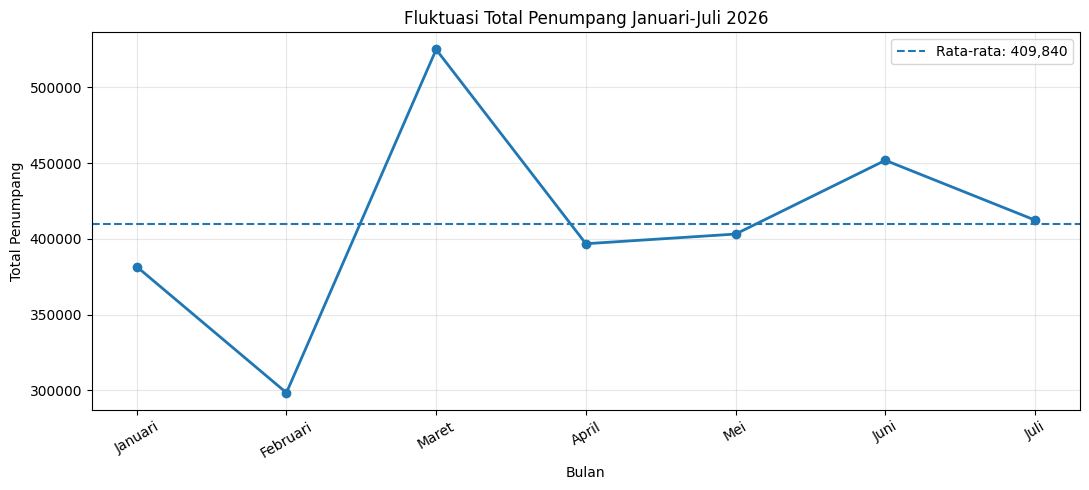

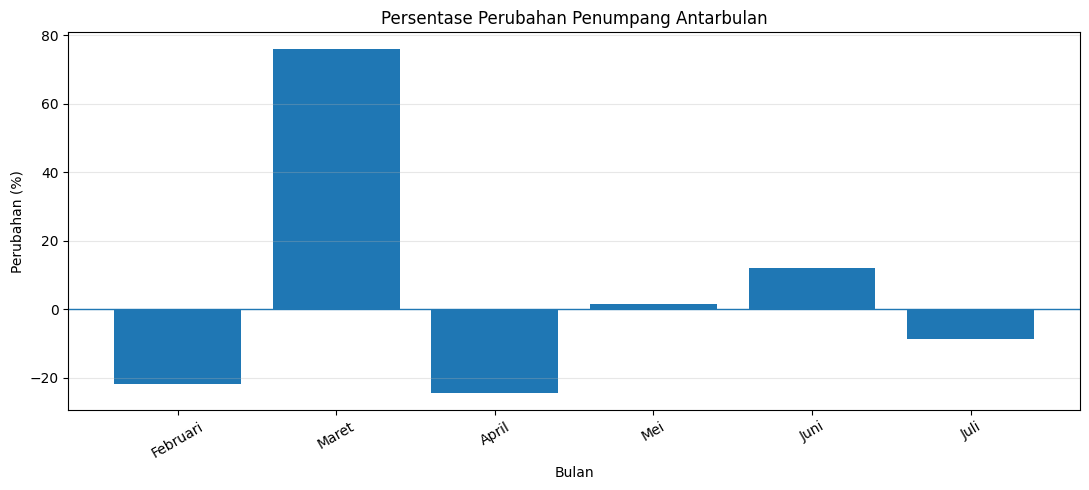

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# ANALISIS FLUKTUASI DAN KONSISTENSI BULANAN
# PERIODE JANUARI-JULI 2026
# ==========================================

bulan_nama = {
    1: "Januari",
    2: "Februari",
    3: "Maret",
    4: "April",
    5: "Mei",
    6: "Juni",
    7: "Juli"
}

urutan_bulan = list(bulan_nama.values())

# 1. Total penumpang setiap bulan (Menggunakan penumpang_keseluruhan)
data_analisis = penumpang_keseluruhan.copy()
data_analisis["DEPART TIME"] = pd.to_datetime(data_analisis["DEPART TIME"], errors="coerce")
data_analisis["BULAN_KE"] = data_analisis["DEPART TIME"].dt.month

total_bulanan = (
    data_analisis.groupby("BULAN_KE")["TOTAL PSG"]
    .sum()
    .reindex(range(1, 8), fill_value=0)
)

total_bulanan.index = urutan_bulan

# 2. Perubahan jumlah dan persentase antarbulan
analisis_bulanan = pd.DataFrame({
    "Total Penumpang": total_bulanan
})

analisis_bulanan["Perubahan Penumpang"] = (
    analisis_bulanan["Total Penumpang"].diff()
)

analisis_bulanan["Perubahan (%)"] = (
    analisis_bulanan["Total Penumpang"].pct_change() * 100
)

# 3. Ukuran fluktuasi dan konsistensi
rata_rata = analisis_bulanan["Total Penumpang"].mean()
simpangan_baku = analisis_bulanan["Total Penumpang"].std()

# Koefisien variasi: makin kecil, makin konsisten
cv = (simpangan_baku / rata_rata * 100) if rata_rata != 0 else np.nan

# 4. Identifikasi kenaikan dan penurunan
analisis_bulanan["Arah Perubahan"] = (
    analisis_bulanan["Perubahan Penumpang"]
    .apply(
        lambda x: "Awal periode" if pd.isna(x)
        else "Naik" if x > 0
        else "Turun" if x < 0
        else "Tetap"
    )
)

print("TABEL FLUKTUASI PENUMPANG BULANAN")
display(analisis_bulanan.round(2))

# 5. Ringkasan statistik
bulan_tertinggi = total_bulanan.idxmax()
bulan_terendah = total_bulanan.idxmin()

print("\nRINGKASAN FLUKTUASI DAN KONSISTENSI")
print(f"Rata-rata penumpang per bulan : {rata_rata:,.2f}")
print(f"Simpangan baku bulanan        : {simpangan_baku:,.2f}")
print(f"Koefisien variasi (CV)        : {cv:.2f}%")
print(f"Bulan dengan penumpang tertinggi: {bulan_tertinggi}")
print(f"Bulan dengan penumpang terendah : {bulan_terendah}")

# 6. Grafik total penumpang
plt.figure(figsize=(11, 5))
plt.plot(
    urutan_bulan,
    total_bulanan.values,
    marker="o",
    linewidth=2
)
plt.axhline(
    rata_rata,
    linestyle="--",
    label=f"Rata-rata: {rata_rata:,.0f}"
)
plt.title("Fluktuasi Total Penumpang Januari-Juli 2026")
plt.xlabel("Bulan")
plt.ylabel("Total Penumpang")
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 7. Grafik persentase perubahan bulanan
perubahan = analisis_bulanan["Perubahan (%)"].dropna()

plt.figure(figsize=(11, 5))
plt.bar(perubahan.index, perubahan.values)
plt.axhline(0, linewidth=1)
plt.title("Persentase Perubahan Penumpang Antarbulan")
plt.xlabel("Bulan")
plt.ylabel("Perubahan (%)")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

TABEL POLA PENUMPANG PER BULAN


,Bulan,Stasiun Terendah,Jumlah Terendah,Stasiun Sedang,Jumlah Sedang,Stasiun Tertinggi,Jumlah Tertinggi
0,Januari,KBS,371.0,SLW,10306.0,PWT,141259.0
1,Februari,KBS,321.0,BMA,9350.0,PWT,116092.0
2,Maret,KBS,400.0,SLW,13961.0,PWT,175235.0
3,April,KBS,401.0,BMA,12188.0,PWT,145663.0
4,Mei,KBS,367.0,BMA,11448.0,PWT,164013.0
5,Juni,KBS,481.0,SLW,14499.0,PWT,172343.0
6,Juli,KBS,397.0,BMA,12369.0,PWT,161835.0


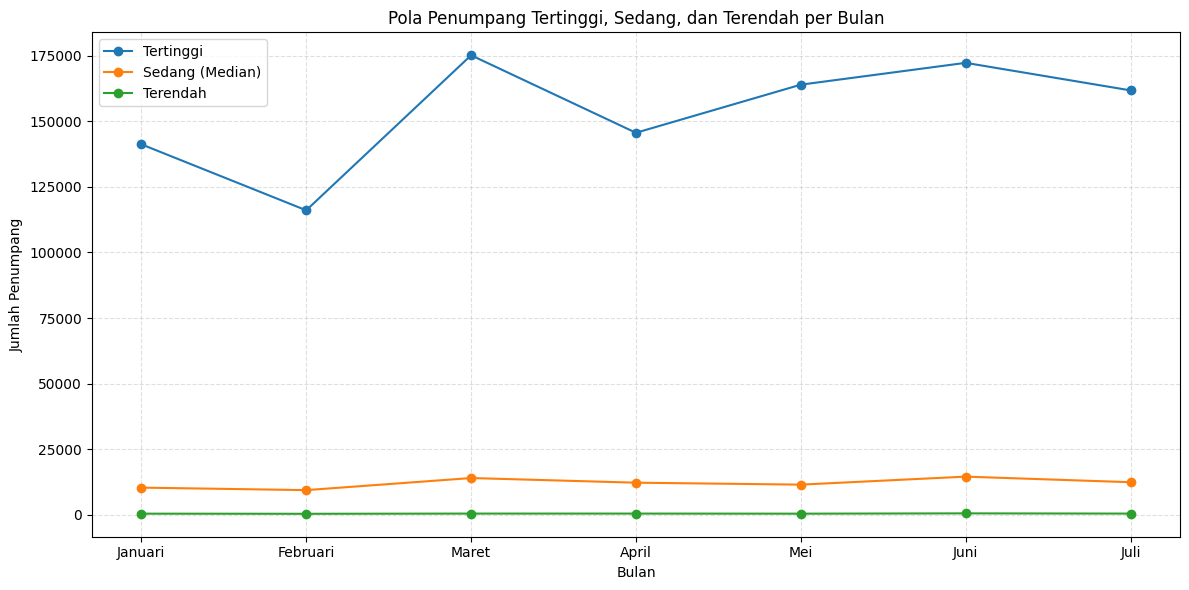

In [ ]:

# ==========================================
# POLA PENUMPANG TERTINGGI, SEDANG, TERENDAH
# JANUARI-JULI 2026
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

hasil_pola = []

for b in bulan:
    data = permintaan_stasiun[b].sort_values()

    # Stasiun dengan jumlah penumpang terendah
    stasiun_rendah = data.index[0]

    # Stasiun dengan jumlah penumpang median
    stasiun_sedang = data.index[len(data) // 2]

    # Stasiun dengan jumlah penumpang tertinggi
    stasiun_tinggi = data.index[-1]

    hasil_pola.append({
        "Bulan": b,
        "Stasiun Terendah": stasiun_rendah,
        "Jumlah Terendah": data.iloc[0],
        "Stasiun Sedang": stasiun_sedang,
        "Jumlah Sedang": data.iloc[len(data) // 2],
        "Stasiun Tertinggi": stasiun_tinggi,
        "Jumlah Tertinggi": data.iloc[-1]
    })

tabel_pola = pd.DataFrame(hasil_pola)

print("TABEL POLA PENUMPANG PER BULAN")
display(tabel_pola)

# Grafik garis
plt.figure(figsize=(12, 6))

plt.plot(
    bulan, tabel_pola["Jumlah Tertinggi"],
    marker="o", label="Tertinggi"
)

plt.plot(
    bulan, tabel_pola["Jumlah Sedang"],
    marker="o", label="Sedang (Median)"
)

plt.plot(
    bulan, tabel_pola["Jumlah Terendah"],
    marker="o", label="Terendah"
)

plt.title("Pola Penumpang Tertinggi, Sedang, dan Terendah per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Penumpang")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.preprocessing import StandardScaler

# 1. Menentukan urutan 18 stasiun DAOP 5
daop5 = [
    'PWT', 'KYA', 'KTA', 'CP', 'KM', 'GB',
    'BMA', 'SLW', 'PPK', 'SDR', 'MA', 'KWN',
    'GM', 'GDM', 'KA', 'SPH', 'JRL', 'KBS'
]

# 2. Mengambil data permintaan bulanan setiap stasiun
X = permintaan_stasiun.reindex(daop5).fillna(0)

# 3. Standardisasi data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Memeriksa hasil
print("Ukuran data:", X.shape)
print("Ukuran data setelah standardisasi:", X_scaled.shape)

display(X.head())


Ukuran data: (18, 7)
Ukuran data setelah standardisasi: (18, 7)


,Januari,Februari,Maret,April,Mei,Juni,Juli
ORG,,,,,,,
PWT,141259.0,116092.0,175235.0,145663.0,164013.0,172343.0,161835.0
KYA,45676.0,33994.0,60095.0,46834.0,44740.0,52244.0,47360.0
KTA,50476.0,38419.0,89287.0,51598.0,50662.0,57675.0,52461.0
CP,20134.0,16482.0,15964.0,21129.0,23722.0,24033.0,19873.0
KM,30703.0,21719.0,51049.0,31235.0,28103.0,33570.0,29846.0


Segmentasi stasiun dengan K-Means

In [ ]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Menyimpan hasil pengujian parameter
hasil_parameter = []

# Menguji beberapa kombinasi parameter
for k in [2, 3, 4, 5]:
    for init_method in ["k-means++", "random"]:
        for n_init_value in [10, 20, 50]:

            model = KMeans(
                n_clusters=k,
                init=init_method,
                n_init=n_init_value,
                max_iter=300,
                random_state=42
            )

            labels = model.fit_predict(X_scaled)

            hasil_parameter.append({
                "Jumlah Cluster": k,
                "Init": init_method,
                "N Init": n_init_value,
                "Inertia": round(model.inertia_, 3),
                "Silhouette Score": round(
                    silhouette_score(X_scaled, labels), 3
                ),
                "Jumlah Iterasi": model.n_iter_
            })

# Membuat tabel hasil eksperimen
hasil_uji_parameter = pd.DataFrame(hasil_parameter)

# Mengurutkan berdasarkan Silhouette Score tertinggi
hasil_uji_parameter = hasil_uji_parameter.sort_values(
    "Silhouette Score",
    ascending=False
).reset_index(drop=True)

display(hasil_uji_parameter)


,Jumlah Cluster,Init,N Init,Inertia,Silhouette Score,Jumlah Iterasi
0,2,k-means++,10,23.853,0.818,2
1,2,k-means++,20,23.853,0.818,2
2,2,k-means++,50,23.853,0.818,2
3,2,random,10,23.853,0.818,7
4,2,random,20,23.853,0.818,7
5,2,random,50,23.853,0.818,7
6,3,k-means++,10,5.424,0.666,2
7,3,k-means++,20,5.424,0.666,2
8,3,k-means++,50,5.424,0.666,2
9,3,random,10,5.424,0.666,9


Parameter	Nilai yang diuji	Fungsi
n_clusters	2, 3, 4, 5	Menentukan jumlah kelompok stasiun.
init	k-means++, random	Menentukan cara memilih centroid awal.
n_init	10, 20, 50	Jumlah percobaan inisialisasi untuk setiap model.
max_iter	300	Batas maksimum iterasi per percobaan.
random_state	42	Membantu eksperimen menghasilkan hasil yang dapat direproduksi.

3 cluster dengan init = k-means++ dan n_init = 10.


MEMBANDINGKAN CLUSTER 2 DAN 3

In [ ]:

from sklearn.cluster import KMeans
import pandas as pd

hasil_perbandingan = {}

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels = model.fit_predict(X_scaled)

    hasil_cluster = X.copy()
    hasil_cluster["Cluster"] = labels

    hasil_perbandingan[k] = hasil_cluster

    print(f"\nHASIL K-MEANS DENGAN {k} CLUSTER")

    for cluster in sorted(hasil_cluster["Cluster"].unique()):
        anggota = hasil_cluster.index[
            hasil_cluster["Cluster"] == cluster
        ].tolist()

        print(f"Cluster {cluster}: {', '.join(anggota)}")

    print("\nJumlah stasiun per cluster:")
    display(
        hasil_cluster["Cluster"]
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .reset_index(name="Jumlah Stasiun")
    )



HASIL K-MEANS DENGAN 2 CLUSTER
Cluster 0: KYA, KTA, CP, KM, GB, BMA, SLW, PPK, SDR, MA, KWN, GM, GDM, KA, SPH, JRL, KBS
Cluster 1: PWT

Jumlah stasiun per cluster:


,Cluster,Jumlah Stasiun
0,0,17
1,1,1



HASIL K-MEANS DENGAN 3 CLUSTER
Cluster 0: CP, GB, BMA, SLW, PPK, SDR, MA, KWN, GM, GDM, KA, SPH, JRL, KBS
Cluster 1: PWT
Cluster 2: KYA, KTA, KM

Jumlah stasiun per cluster:


,Cluster,Jumlah Stasiun
0,0,14
1,1,1
2,2,3


In [ ]:

from sklearn.cluster import KMeans
import pandas as pd

# Menjalankan model final dengan 3 cluster
model_final = KMeans(
    n_clusters=3,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

hasil_cluster = X.copy()
hasil_cluster["Cluster"] = model_final.fit_predict(X_scaled)

# Memberikan label pada setiap cluster
label_cluster = {
    0: "Permintaan Rendah",
    1: "Permintaan Tinggi",
    2: "Permintaan Menengah"
}

hasil_cluster["Label Cluster"] = (
    hasil_cluster["Cluster"].map(label_cluster)
)

# Menghitung total permintaan selama Januari-Juli
kolom_bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

hasil_cluster["Total Jan-Jul"] = (
    hasil_cluster[kolom_bulan].sum(axis=1)
)

# Menghitung rata-rata penumpang bulanan per stasiun
hasil_cluster["Rata-rata Bulanan"] = (
    hasil_cluster["Total Jan-Jul"] / 7
)

# Ringkasan karakteristik cluster
ringkasan_cluster = (
    hasil_cluster.groupby(["Cluster", "Label Cluster"])
    .agg(
        Jumlah_Stasiun=("Total Jan-Jul", "size"),
        Total_Penumpang=("Total Jan-Jul", "sum"),
        Rata_Rata_Total_Stasiun=("Total Jan-Jul", "mean"),
        Rata_Rata_Bulanan_Stasiun=("Rata-rata Bulanan", "mean")
    )
    .round(2)
    .reset_index()
)

print("RINGKASAN KARAKTERISTIK CLUSTER")
display(ringkasan_cluster)

# Detail stasiun beserta label cluster
print("DETAIL STASIUN DAN CLUSTER")
display(
    hasil_cluster[
        [
            "Cluster",
            "Label Cluster",
            "Total Jan-Jul",
            "Rata-rata Bulanan"
        ]
    ].sort_values(["Cluster", "Total Jan-Jul"],
                  ascending=[True, False])
)


RINGKASAN KARAKTERISTIK CLUSTER


,Cluster,Label Cluster,Jumlah_Stasiun,Total_Penumpang,Rata_Rata_Total_Stasiun,Rata_Rata_Bulanan_Stasiun
0,0,Permintaan Rendah,14,844693.0,60335.21,8619.32
1,1,Permintaan Tinggi,1,1076440.0,1076440.00,153777.14
2,2,Permintaan Menengah,3,947746.0,315915.33,45130.76


DETAIL STASIUN DAN CLUSTER


,Cluster,Label Cluster,Total Jan-Jul,Rata-rata Bulanan
ORG,,,,
GB,0,Permintaan Rendah,163143.0,23306.142857
CP,0,Permintaan Rendah,141337.0,20191.000000
SDR,0,Permintaan Rendah,98638.0,14091.142857
BMA,0,Permintaan Rendah,91876.0,13125.142857
SLW,0,Permintaan Rendah,87156.0,12450.857143
MA,0,Permintaan Rendah,61938.0,8848.285714
GM,0,Permintaan Rendah,49453.0,7064.714286
GDM,0,Permintaan Rendah,36723.0,5246.142857
KA,0,Permintaan Rendah,30489.0,4355.571429


algoritma K-Means dengan \(k=3\), sebanyak 18 stasiun KAI DAOP 5 Purwokerto terbagi menjadi tiga kelompok berdasarkan pola permintaan penumpang Januari–Juli 2026. Cluster 0 terdiri atas 14 stasiun dengan total 844.693 penumpang dan rata-rata 8.619,32 penumpang per stasiun per bulan, sehingga merepresentasikan kelompok stasiun dengan permintaan relatif rendah. Cluster 1 hanya terdiri atas Stasiun PWT dengan total 1.076.440 penumpang dan rata-rata 153.777,14 penumpang per bulan, menjadikannya kelompok dengan permintaan paling tinggi. Sementara itu, Cluster 2 terdiri atas Stasiun KM, KTA, dan KYA dengan total 947.746 penumpang serta rata-rata 45.130,76 penumpang per stasiun per bulan, sehingga merepresentasikan kelompok dengan permintaan menengah.

In [ ]:

import pandas as pd
import plotly.express as px

# Menyalin data permintaan bulanan
bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

# Mengubah data menjadi format panjang untuk grafik interaktif
data_plot = (
    permintaan_stasiun[bulan]
    .reset_index(names="Stasiun")
    .melt(
        id_vars="Stasiun",
        var_name="Bulan",
        value_name="Jumlah Penumpang"
    )
)

# Menentukan urutan bulan
data_plot["Bulan"] = pd.Categorical(
    data_plot["Bulan"],
    categories=bulan,
    ordered=True
)

# Membuat grafik interaktif
fig = px.line(
    data_plot,
    x="Bulan",
    y="Jumlah Penumpang",
    color="Stasiun",
    markers=True,
    title="Pola Permintaan Penumpang per Stasiun, Januari–Juli 2026",
    hover_data={
        "Stasiun": True,
        "Bulan": True,
        "Jumlah Penumpang": ":,.0f"
    }
)

fig.update_layout(
    xaxis_title="Bulan",
    yaxis_title="Jumlah Penumpang",
    hovermode="closest",
    template="plotly_white",
    legend_title="Stasiun",
    height=650
)

fig.update_traces(
    marker=dict(size=7),
    line=dict(width=2)
)

fig.show()


In [ ]:

import pandas as pd
import plotly.express as px

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

# Menggabungkan label cluster dengan data bulanan
data_cluster = permintaan_stasiun.copy()

data_cluster["Cluster"] = hasil_cluster["Cluster"]
data_cluster["Label Cluster"] = hasil_cluster["Label Cluster"]

# Menghitung rata-rata jumlah penumpang per stasiun
# untuk setiap cluster pada masing-masing bulan
rata_cluster = (
    data_cluster
    .groupby(["Cluster", "Label Cluster"])[bulan]
    .mean()
    .reset_index()
)

# Mengubah data ke format panjang untuk Plotly
data_plot_cluster = rata_cluster.melt(
    id_vars=["Cluster", "Label Cluster"],
    value_vars=bulan,
    var_name="Bulan",
    value_name="Rata-rata Penumpang per Stasiun"
)

data_plot_cluster["Bulan"] = pd.Categorical(
    data_plot_cluster["Bulan"],
    categories=bulan,
    ordered=True
)

# Grafik interaktif pola permintaan per cluster
fig = px.line(
    data_plot_cluster,
    x="Bulan",
    y="Rata-rata Penumpang per Stasiun",
    color="Label Cluster",
    markers=True,
    hover_data={
        "Cluster": True,
        "Label Cluster": True,
        "Rata-rata Penumpang per Stasiun": ":,.2f"
    },
    title="Pola Permintaan Bulanan Berdasarkan Cluster Stasiun"
)

fig.update_layout(
    template="plotly_white",
    hovermode="closest",
    height=550,
    xaxis_title="Bulan",
    yaxis_title="Rata-rata Penumpang per Stasiun"
)

fig.show()


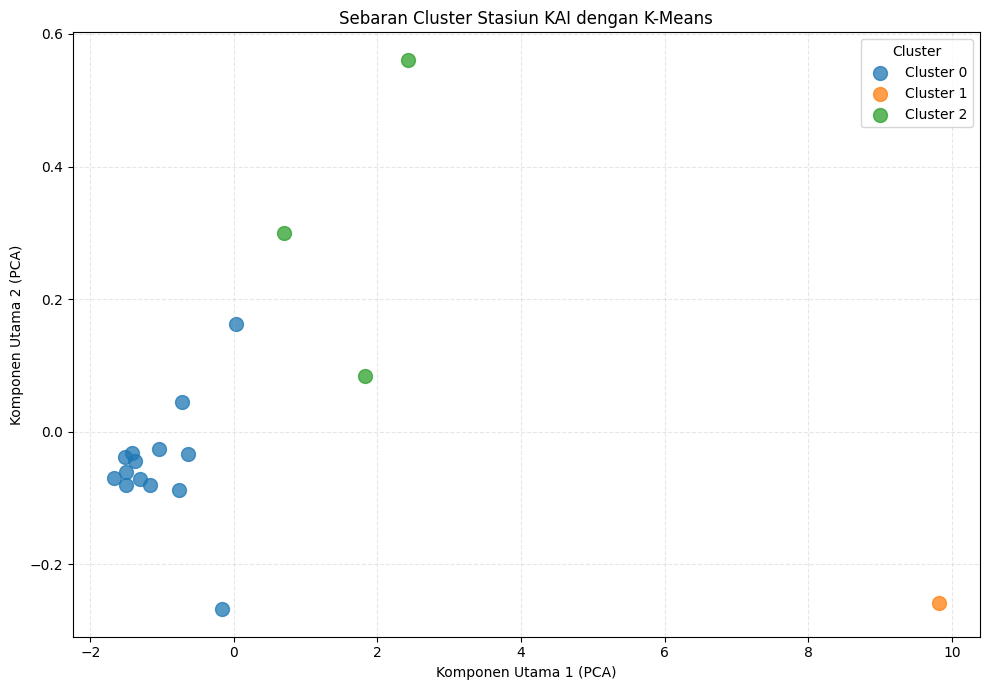

In [ ]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ==========================================
# VISUALISASI SEBARAN 3 CLUSTER K-MEANS
# ==========================================

# Gunakan fitur yang sama dengan model K-Means
# X_scaled adalah data yang sudah distandardisasi

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))

for cluster in sorted(hasil_cluster["Cluster"].unique()):
    mask = hasil_cluster["Cluster"].to_numpy() == cluster

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        s=100,
        alpha=0.75
    )

plt.title("Sebaran Cluster Stasiun KAI dengan K-Means")
plt.xlabel("Komponen Utama 1 (PCA)")
plt.ylabel("Komponen Utama 2 (PCA)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


tren pertumbuhan stasiun

In [ ]:
import pandas as pd
import numpy as np

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

# Mengambil data permintaan penumpang per stasiun
data_tren_stasiun = permintaan_stasiun[bulan].copy()

# Menghitung persentase perubahan bulanan setiap stasiun
perubahan_stasiun = data_tren_stasiun.pct_change(
    axis=1
) * 100

# Menambahkan identitas stasiun
perubahan_stasiun.index.name = "Stasiun"
perubahan_stasiun = perubahan_stasiun.reset_index()

# Menampilkan hasil persentase perubahan
display(perubahan_stasiun.round(2))

,Stasiun,Januari,Februari,Maret,April,Mei,Juni,Juli
0,BMA,NaN,-22.13,108.22,-37.40,-6.07,31.42,-17.79
1,CP,NaN,-18.14,-3.14,32.35,12.27,1.31,-17.31
2,GB,NaN,-28.91,125.67,-33.69,-14.55,24.74,-12.10
3,GDM,NaN,-29.11,51.91,2.49,-15.98,22.97,-13.17
4,GM,NaN,-18.06,57.79,-19.72,15.14,13.34,-1.31
5,JRL,NaN,-24.27,22.06,5.32,-0.87,2.82,5.49
6,KA,NaN,-22.53,83.82,-19.35,-18.80,23.13,-11.11
7,KBS,NaN,-13.48,24.61,0.25,-8.48,31.06,-17.46
8,KM,NaN,-29.26,135.04,-38.81,-10.03,19.45,-11.09
9,KTA,NaN,-23.89,132.40,-42.21,-1.81,13.84,-9.04


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import linregress

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

hasil_tren_stasiun = []

for stasiun, row in permintaan_stasiun[bulan].iterrows():
    nilai = row.astype(float).values
    x = np.arange(len(nilai))

    slope, intercept, r_value, p_value, std_err = linregress(
        x, nilai
    )

    total_awal = nilai[0]
    total_akhir = nilai[-1]

    perubahan_total = (
        (total_akhir - total_awal) / total_awal * 100
        if total_awal != 0 else np.nan
    )

    hasil_tren_stasiun.append({
        "Stasiun": stasiun,
        "Rata-rata Penumpang": nilai.mean(),
        "Perubahan Jan-Jul (%)": perubahan_total,
        "Tren per Bulan": slope,
        "R-squared": r_value ** 2,
        "P-value": p_value
    })

hasil_tren_stasiun = pd.DataFrame(hasil_tren_stasiun)

hasil_tren_stasiun["Arah Tren"] = np.where(
    hasil_tren_stasiun["Tren per Bulan"] > 0,
    "Meningkat",
    np.where(
        hasil_tren_stasiun["Tren per Bulan"] < 0,
        "Menurun",
        "Stabil"
    )
)

display(
    hasil_tren_stasiun
    .sort_values("Tren per Bulan", ascending=False)
    .round(3)
)

,Stasiun,Rata-rata Penumpang,Perubahan Jan-Jul (%),Tren per Bulan,R-squared,P-value,Arah Tren
14,PWT,153777.143,14.566,5821.714,0.363,0.153,Meningkat
11,KYA,47277.571,3.687,935.607,0.065,0.580,Meningkat
1,CP,20191.000,-1.296,788.464,0.291,0.212,Meningkat
16,SLW,12450.857,30.021,612.143,0.546,0.058,Meningkat
4,GM,7064.714,33.691,435.821,0.577,0.048,Meningkat
15,SDR,14091.143,8.690,362.893,0.118,0.451,Meningkat
9,KTA,55796.857,3.933,208.643,0.001,0.952,Meningkat
12,MA,8848.286,9.232,178.000,0.055,0.614,Meningkat
0,BMA,13125.143,3.015,159.107,0.011,0.822,Meningkat
3,GDM,5246.143,-0.984,129.143,0.133,0.422,Meningkat


Stasiun dengan indikasi pertumbuhan yang menonjol
- GM: perubahan Januari–Juli sebesar 33,69%, dengan \(R^2=0{,}577\) dan p-value 0,048.
- SLW: perubahan sebesar 30,02%, dengan \(R^2=0{,}546\) dan p-value 0,058.
- PWT: perubahan sebesar 14,57%, dengan tren kenaikan sekitar 5.821,71 penumpang per bulan.
GM menunjukkan tren linear yang signifikan pada ambang 5% berdasarkan hasil yang ditampilkan. SLW mendekati ambang tersebut, sedangkan tren PWT belum signifikan.




Stasiun dengan indikasi penurunan
- KWN: perubahan Januari–Juli sebesar −10,75%.
- KM: perubahan Januari–Juli sebesar −2,79%.
Keduanya memiliki p-value yang tinggi, sehingga data ini belum memberikan bukti statistik yang cukup untuk menyimpulkan adanya tren penurunan linear.

Perubahan Jan–Jul (%) dihitung berdasarkan perbandingan jumlah penumpang bulan Januari dan Juli pada setiap stasiun.



In [ ]:
import plotly.express as px

data_grafik_tren = hasil_tren_stasiun.sort_values(
    "Tren per Bulan", ascending=True
).copy()

fig = px.bar(
    data_grafik_tren,
    x="Tren per Bulan",
    y="Stasiun",
    color="Arah Tren",
    orientation="h",
    hover_data={
        "Perubahan Jan-Jul (%)": ":.2f",
        "R-squared": ":.3f",
        "P-value": ":.3f",
        "Tren per Bulan": ":.2f"
    },
    title="Tren Perubahan Permintaan Penumpang per Stasiun"
)

fig.add_vline(x=0, line_dash="dash", line_color="gray")

fig.update_layout(
    template="plotly_white",
    xaxis_title="Tren Linear (Penumpang per Bulan)",
    yaxis_title="Stasiun",
    height=650
)

fig.show()

Segmentasi rute ORG–DES

In [ ]:

import pandas as pd

# Salin data utama
df_rute = penumpang_keseluruhan.copy()

# Bersihkan kolom yang diperlukan
df_rute["ORG"] = (
    df_rute["ORG"].astype("string").str.strip().str.upper()
)
df_rute["DES"] = (
    df_rute["DES"].astype("string").str.strip().str.upper()
)
df_rute["TOTAL PSG"] = pd.to_numeric(
    df_rute["TOTAL PSG"], errors="coerce"
)
df_rute["DEPART TIME"] = pd.to_datetime(
    df_rute["DEPART TIME"], errors="coerce"
)

df_rute = df_rute.dropna(
    subset=["ORG", "DES", "TOTAL PSG", "DEPART TIME"]
).copy()

# Filter Januari–Juli 2026
df_rute = df_rute[
    (df_rute["DEPART TIME"].dt.year == 2026) &
    (df_rute["DEPART TIME"].dt.month.between(1, 7))
].copy()

# Hapus data dengan asal dan tujuan sama
df_rute = df_rute[df_rute["ORG"] != df_rute["DES"]].copy()

# Buat kolom bulan
df_rute["BULAN_KE"] = df_rute["DEPART TIME"].dt.month

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

# Hitung total penumpang setiap rute per bulan
permintaan_rute = (
    df_rute.groupby(["ORG", "DES", "BULAN_KE"])["TOTAL PSG"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 8), fill_value=0)
)

permintaan_rute.columns = bulan

# Hitung total penumpang selama 7 bulan
permintaan_rute["Total Jan-Jul"] = (
    permintaan_rute[bulan].sum(axis=1)
)

# Periksa hasil
print("Jumlah rute yang berhasil diidentifikasi:",
      len(permintaan_rute))

display(
    permintaan_rute.sort_values(
        "Total Jan-Jul", ascending=False
    ).head(20)
)


Jumlah rute yang berhasil diidentifikasi: 1294


Januari  Februari    Maret    April      Mei     Juni     Juli  \
ORG DES                                                                   
PWT YK   17836.0   14970.0  18173.0  18026.0  21059.0  21209.0  21298.0   
    PSE  17158.0   13110.0  19155.0  16991.0  16278.0  18168.0  16184.0   
    GMR  15494.0   11186.0  19948.0  13639.0  15981.0  17806.0  18171.0   
KTA PSE  10534.0    8280.0  20557.0  11449.0   9847.0  12026.0  10042.0   
PWT CN    7284.0    6437.0   7636.0   8411.0  10253.0   9500.0   9168.0   
KM  PSE   7498.0    5128.0  12289.0   8107.0   6113.0   7983.0   6790.0   
PWT BKS   7292.0    4986.0  10147.0   6757.0   7433.0   8630.0   8035.0   
    CP    6467.0    6224.0   2542.0   8413.0  11684.0  11665.0   6215.0   
KTA KAC   7638.0    4844.0   9174.0   7233.0   6934.0   7988.0   7578.0   
PWT LPN   6682.0    5978.0   7080.0   6662.0   7930.0   7678.0   8094.0   
CP  PWT   6334.0    5676.0   2620.0   8320.0  10023.0   9877.0   5693.0   
KYA PSE   6931.0    5128.0   8207.0   7561.0   5746.0   7675.0   6032.0   
PWT SMC   5665.0    5773.0   6732.0   6428.0   7071.0   7467.0   6977.0   
KYA YK    5864.0    5009.0   5940.0   6328.0   7227.0   7615.0   7801.0   
KTA YK    5186.0    4913.0   8061.0   5937.0   6847.0   7017.0   6554.0   
PWT JNG   6104.0    4903.0   7577.0   5573.0   6315.0   7012.0   6126.0   
    SLO   5265.0    4374.0   6865.0   4785.0   5784.0   5847.0   5457.0   
KTA BKS   4534.0    3035.0   8556.0   4269.0   3589.0   4684.0   4039.0   
GB  PSE   4427.0    3351.0   6730.0   5000.0   3718.0   4769.0   4034.0   
PWT TG    3461.0    3417.0   5002.0   4292.0   4599.0   4760.0   4753.0   

         Total Jan-Jul  
ORG DES                 
PWT YK        132571.0  
    PSE       117044.0  
    GMR       112225.0  
KTA PSE        82735.0  
PWT CN         58689.0  
KM  PSE        53908.0  
PWT BKS        53280.0  
    CP         53210.0  
KTA KAC        51389.0  
PWT LPN        50104.0  
CP  PWT        48543.0  
KYA PSE        47280.0  
PWT SMC        46113.0  
KYA YK         45784.0  
KTA YK         44515.0  
PWT JNG        43610.0  
    SLO        38377.0  
KTA BKS        32706.0  
GB  PSE        32029.0  
PWT TG         30284.0

data penumpang KAI periode Januari–Juli 2026, diperoleh sebanyak 1.294 pasangan rute asal–tujuan (ORG–DES) yang unik. Setiap rute direkapitulasi berdasarkan jumlah penumpang bulanan dan total penumpang selama periode pengamatan. Hasil pengurutan berdasarkan total penumpang menunjukkan bahwa rute PWT–YK memiliki jumlah penumpang tertinggi pada tabel, yaitu 132.571 penumpang, diikuti oleh rute PWT–PSE sebanyak 117.044 penumpang dan PWT–GMR sebanyak 112.225 penumpang.

Perbedaan jumlah penumpang antarrute menunjukkan adanya variasi tingkat permintaan perjalanan. Oleh karena itu, analisis dilanjutkan menggunakan algoritma K-Means untuk mengelompokkan rute berdasarkan karakteristik permintaan penumpang bulanan ke dalam tiga kelompok, yaitu permintaan rendah, menengah, dan tinggi. Hasil pengelompokan diharapkan dapat memberikan gambaran mengenai distribusi permintaan antarrute sebagai dasar analisis lebih lanjut.

In [ ]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Menentukan fitur permintaan rute per bulan
bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

X_rute = permintaan_rute[bulan].copy()

# 2. Standardisasi data rute
scaler_rute = StandardScaler()
X_rute_scaled = scaler_rute.fit_transform(X_rute)

# 3. Menyimpan hasil pengujian parameter
hasil_parameter_rute = []

# 4. Menguji beberapa kombinasi parameter
for k in [2, 3, 4, 5]:
    for init_method in ["k-means++", "random"]:
        for n_init_value in [10, 20, 50]:

            model = KMeans(
                n_clusters=k,
                init=init_method,
                n_init=n_init_value,
                max_iter=300,
                random_state=42
            )

            labels = model.fit_predict(X_rute_scaled)

            hasil_parameter_rute.append({
                "Jumlah Cluster": k,
                "Init": init_method,
                "N Init": n_init_value,
                "Inertia": round(model.inertia_, 3),
                "Silhouette Score": round(
                    silhouette_score(X_rute_scaled, labels), 3
                ),
                "Jumlah Iterasi": model.n_iter_
            })

# 5. Membuat tabel hasil eksperimen
hasil_uji_parameter_rute = pd.DataFrame(
    hasil_parameter_rute
)

# 6. Mengurutkan berdasarkan Silhouette Score tertinggi
hasil_uji_parameter_rute = (
    hasil_uji_parameter_rute
    .sort_values(
        "Silhouette Score",
        ascending=False
    )
    .reset_index(drop=True)
)

# 7. Menampilkan hasil pengujian
display(hasil_uji_parameter_rute)


In [ ]:

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

hasil_perbandingan_rute = {}

for k in [2, 3]:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels = model.fit_predict(X_rute_scaled)

    hasil_cluster_rute = permintaan_rute.copy()
    hasil_cluster_rute["Cluster"] = labels

    hasil_perbandingan_rute[k] = hasil_cluster_rute

    print(f"\nHASIL K-MEANS RUTE DENGAN {k} CLUSTER")
    print(
        "Silhouette Score:",
        round(silhouette_score(X_rute_scaled, labels), 4)
    )

    print("\nJumlah rute per cluster:")
    display(
        hasil_cluster_rute["Cluster"]
        .value_counts()
        .sort_index()
        .rename_axis("Cluster")
        .reset_index(name="Jumlah Rute")
    )


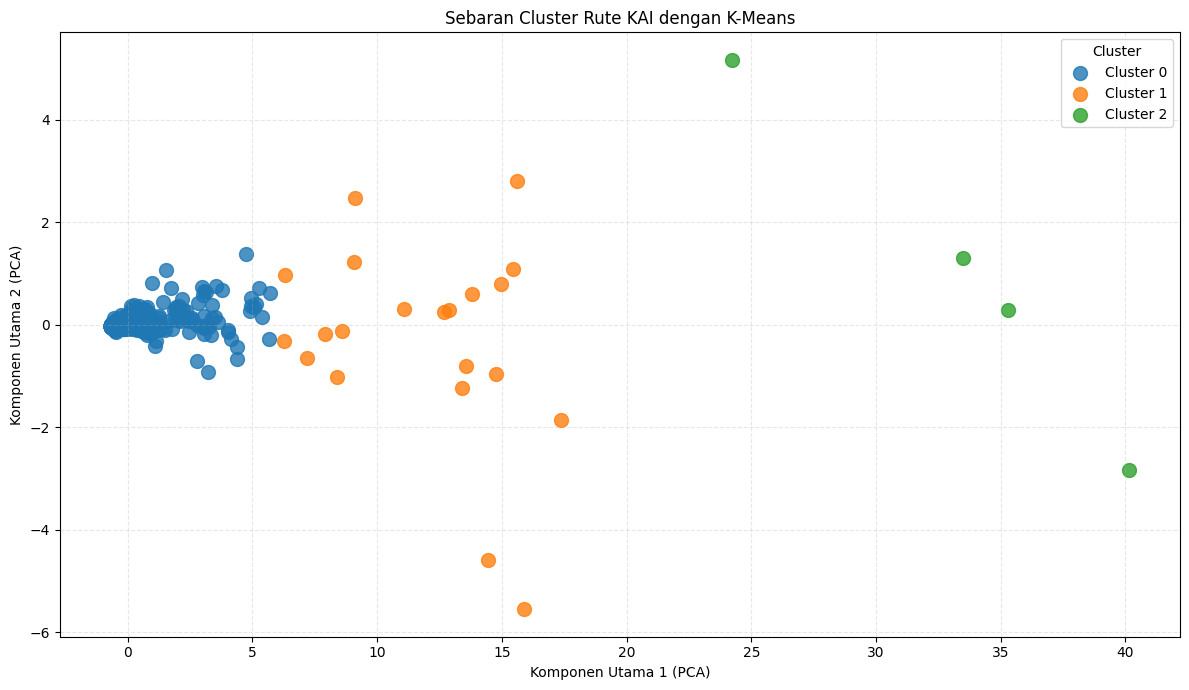

Total variansi yang dijelaskan PCA: 99.45%


In [ ]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# ==========================================
# VISUALISASI PERSEBARAN CLUSTER RUTE KAI
# K-MEANS DENGAN PCA
# ==========================================

# Pilih jumlah cluster yang ingin divisualisasikan
k = 3

# Ambil label cluster dari model yang sudah diuji
label_cluster = hasil_perbandingan_rute[k]["Cluster"].to_numpy()

# Reduksi 7 fitur bulanan menjadi 2 dimensi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_rute_scaled)

# Buat scatter plot
plt.figure(figsize=(12, 7))

for cluster in sorted(set(label_cluster)):
    mask = label_cluster == cluster

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=100,
        alpha=0.8,
        label=f"Cluster {cluster}"
    )

plt.title("Sebaran Cluster Rute KAI dengan K-Means")
plt.xlabel("Komponen Utama 1 (PCA)")
plt.ylabel("Komponen Utama 2 (PCA)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f"Total variansi yang dijelaskan PCA: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

In [ ]:

import pandas as pd

# Mengambil hasil K-Means dengan 3 cluster
detail_rute = hasil_perbandingan_rute[3].copy()

# Menghitung total penumpang per rute
detail_rute["Total Jan-Jul"] = detail_rute[
    ["Januari", "Februari", "Maret", "April",
     "Mei", "Juni", "Juli"]
].sum(axis=1)

# Menampilkan ringkasan karakteristik cluster
ringkasan_rute = (
    detail_rute.groupby("Cluster")
    .agg(
        Jumlah_Rute=("Total Jan-Jul", "size"),
        Total_Penumpang=("Total Jan-Jul", "sum"),
        Rata_Rata_Penumpang=("Total Jan-Jul", "mean"),
        Median_Penumpang=("Total Jan-Jul", "median"),
        Minimum_Penumpang=("Total Jan-Jul", "min"),
        Maksimum_Penumpang=("Total Jan-Jul", "max")
    )
    .round(2)
    .reset_index()
)

print("RINGKASAN KARAKTERISTIK CLUSTER RUTE")
display(ringkasan_rute)

# Menampilkan seluruh rute berdasarkan cluster
detail_rute = detail_rute.reset_index()
detail_rute["Rute"] = (
    detail_rute["ORG"] + " → " + detail_rute["DES"]
)

print("DETAIL RUTE DALAM SETIAP CLUSTER")
display(
    detail_rute[
        ["ORG", "DES", "Rute",
         "Januari", "Februari", "Maret", "April",
         "Mei", "Juni", "Juli", "Total Jan-Jul",
         "Cluster"]
    ].sort_values(
        ["Cluster", "Total Jan-Jul"],
        ascending=[True, False]
    )
)


In [ ]:

import pandas as pd

# Menggunakan hasil K-Means dengan 3 cluster
hasil_rute_final = hasil_perbandingan_rute[3].copy()

# Menghitung total penumpang Januari-Juli
bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

hasil_rute_final["Total Jan-Jul"] = (
    hasil_rute_final[bulan].sum(axis=1)
)

# Menentukan urutan cluster berdasarkan rata-rata total penumpang
rata_total = (
    hasil_rute_final.groupby("Cluster")["Total Jan-Jul"].mean()
)

urutan = rata_total.sort_values().index.tolist()

label_rute = {
    urutan[0]: "Permintaan Rendah",
    urutan[1]: "Permintaan Menengah",
    urutan[2]: "Permintaan Tinggi"
}

hasil_rute_final["Label Permintaan"] = (
    hasil_rute_final["Cluster"].map(label_rute)
)

# Membuat kolom ORG dan DES menjadi kolom biasa
hasil_rute_final = hasil_rute_final.reset_index()

# Membuat nama rute
hasil_rute_final["Rute"] = (
    hasil_rute_final["ORG"] + " → " + hasil_rute_final["DES"]
)

# Ringkasan akhir
ringkasan_final = (
    hasil_rute_final.groupby("Label Permintaan")
    .agg(
        Jumlah_Rute=("Rute", "count"),
        Total_Penumpang=("Total Jan-Jul", "sum"),
        Rata_Rata_Penumpang=("Total Jan-Jul", "mean")
    )
    .round(2)
    .reset_index()
)

print("RINGKASAN FINAL SEGMENTASI RUTE")
display(ringkasan_final)

print("10 RUTE DENGAN PERMINTAAN TERTINGGI")
display(
    hasil_rute_final[
        ["ORG", "DES", "Rute", "Total Jan-Jul", "Label Permintaan"]
    ]
    .sort_values("Total Jan-Jul", ascending=False)
    .head(10)
)


RINGKASAN FINAL SEGMENTASI RUTE


,Label Permintaan,Jumlah_Rute,Total_Penumpang,Rata_Rata_Penumpang
0,Permintaan Menengah,21,858473.0,40879.67
1,Permintaan Rendah,1269,1565831.0,1233.91
2,Permintaan Tinggi,4,444575.0,111143.75


10 RUTE DENGAN PERMINTAAN TERTINGGI


,ORG,DES,Rute,Total Jan-Jul,Label Permintaan
1127,PWT,YK,PWT → YK,132571.0,Permintaan Tinggi
1099,PWT,PSE,PWT → PSE,117044.0,Permintaan Tinggi
1054,PWT,GMR,PWT → GMR,112225.0,Permintaan Tinggi
665,KTA,PSE,KTA → PSE,82735.0,Permintaan Tinggi
1044,PWT,CN,PWT → CN,58689.0,Permintaan Menengah
560,KM,PSE,KM → PSE,53908.0,Permintaan Menengah
1033,PWT,BKS,PWT → BKS,53280.0,Permintaan Menengah
1047,PWT,CP,PWT → CP,53210.0,Permintaan Menengah
627,KTA,KAC,KTA → KAC,51389.0,Permintaan Menengah
1081,PWT,LPN,PWT → LPN,50104.0,Permintaan Menengah


In [ ]:
# Daftar kode stasiun Daop 5
stasiun_daop5 = [
    "BMA", "CP", "GB", "GDM", "GM", "JRL",
    "KA", "KBS", "KM", "KTA", "KWN", "KYA",
    "MA", "PPK", "PWT", "SDR", "SLW", "SPH"
]

# Filter rute yang asal dan tujuannya sama-sama di Daop 5
rute_daop5 = hasil_rute_final[
    hasil_rute_final["ORG"].isin(stasiun_daop5) &
    hasil_rute_final["DES"].isin(stasiun_daop5)
].copy()

# Ringkasan segmentasi rute Daop 5
ringkasan_daop5 = (
    rute_daop5.groupby("Label Permintaan")
    .agg(
        Jumlah_Rute=("Rute", "count"),
        Total_Penumpang=("Total Jan-Jul", "sum"),
        Rata_Rata_Penumpang=("Total Jan-Jul", "mean")
    )
    .round(2)
    .reset_index()
)

display(ringkasan_daop5)

# Detail rute Daop 5
display(
    rute_daop5[
        ["ORG", "DES", "Rute", "Total Jan-Jul", "Label Permintaan"]
    ].sort_values("Total Jan-Jul", ascending=False)
)

,Label Permintaan,Jumlah_Rute,Total_Penumpang,Rata_Rata_Penumpang
0,Permintaan Menengah,2,101753.0,50876.50
1,Permintaan Rendah,243,336665.0,1385.45


,ORG,DES,Rute,Total Jan-Jul,Label Permintaan
1047,PWT,CP,PWT → CP,53210.0,Permintaan Menengah
114,CP,PWT,CP → PWT,48543.0,Permintaan Menengah
667,KTA,PWT,KTA → PWT,19199.0,Permintaan Rendah
1204,SLW,PWT,SLW → PWT,18929.0,Permintaan Rendah
1074,PWT,KTA,PWT → KTA,18594.0,Permintaan Rendah
...,...,...,...,...,...
482,KBS,PWT,KBS → PWT,2.0,Permintaan Rendah
909,MA,JRL,MA → JRL,2.0,Permintaan Rendah
629,KTA,KBS,KTA → KBS,2.0,Permintaan Rendah
1240,SPH,KA,SPH → KA,2.0,Permintaan Rendah


In [ ]:

import plotly.express as px

# Menghitung jumlah rute per kategori
distribusi_rute = (
    hasil_rute_final["Label Permintaan"]
    .value_counts()
    .rename_axis("Kategori Permintaan")
    .reset_index(name="Jumlah Rute")
)

# Mengatur urutan kategori
urutan_label = [
    "Permintaan Rendah",
    "Permintaan Menengah",
    "Permintaan Tinggi"
]

distribusi_rute["Kategori Permintaan"] = pd.Categorical(
    distribusi_rute["Kategori Permintaan"],
    categories=urutan_label,
    ordered=True
)

distribusi_rute = distribusi_rute.sort_values(
    "Kategori Permintaan"
)

# Membuat grafik batang interaktif
fig = px.bar(
    distribusi_rute,
    x="Kategori Permintaan",
    y="Jumlah Rute",
    text="Jumlah Rute",
    title="Distribusi Rute Berdasarkan Kategori Permintaan",
    hover_data={"Jumlah Rute": True}
)

fig.update_traces(textposition="outside")

fig.update_layout(
    template="plotly_white",
    xaxis_title="Kategori Permintaan",
    yaxis_title="Jumlah Rute",
    height=500
)

fig.show()


In [ ]:
# ==================================================
# DISTRIBUSI KATEGORI RUTE KHUSUS DAOP 5 PURWOKERTO
# ==================================================

# Menghitung jumlah rute per kategori khusus Daop 5
distribusi_rute_daop5 = (
    rute_daop5["Label Permintaan"]
    .value_counts()
    .reindex(urutan_label, fill_value=0)
    .rename_axis("Kategori Permintaan")
    .reset_index(name="Jumlah Rute")
)

# Membuat grafik batang interaktif
fig = px.bar(
    distribusi_rute_daop5,
    x="Kategori Permintaan",
    y="Jumlah Rute",
    text="Jumlah Rute",
    title="Distribusi Rute Daop 5 Purwokerto Berdasarkan Kategori Permintaan",
    category_orders={"Kategori Permintaan": urutan_label}
)

fig.update_traces(textposition="outside")

fig.update_layout(
    template="plotly_white",
    xaxis_title="Kategori Permintaan",
    yaxis_title="Jumlah Rute",
    height=500
)

fig.show()

In [ ]:

import pandas as pd
import plotly.express as px

# Mengambil seluruh rute
semua_rute = hasil_rute_final.copy()

# Mengurutkan rute berdasarkan total penumpang
semua_rute = semua_rute.sort_values(
    "Total Jan-Jul",
    ascending=True
)

# Grafik seluruh rute
fig = px.bar(
    semua_rute,
    x="Total Jan-Jul",
    y="Rute",
    color="Label Permintaan",
    orientation="h",
    hover_data={
        "ORG": True,
        "DES": True,
        "Total Jan-Jul": ":,.0f",
        "Label Permintaan": True
    },
    title="Segmentasi Seluruh Rute ORG–DES, Januari–Juli 2026"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Total Penumpang Januari–Juli 2026",
    yaxis_title="Rute (Asal → Tujuan)",
    height=max(800, len(semua_rute) * 18),
    hovermode="closest",
    showlegend=True
)

fig.show()


In [ ]:
# ==================================================
# SEGMENTASI RUTE KHUSUS DAOP 5 PURWOKERTO
# ==================================================

# Mengambil rute yang asal dan tujuannya sama-sama di Daop 5
rute_daop5 = hasil_rute_final[
    hasil_rute_final["ORG"].isin(stasiun_daop5) &
    hasil_rute_final["DES"].isin(stasiun_daop5)
].copy()

# Mengurutkan rute berdasarkan total penumpang
rute_daop5 = rute_daop5.sort_values(
    "Total Jan-Jul",
    ascending=True
)

# Grafik segmentasi rute Daop 5
fig = px.bar(
    rute_daop5,
    x="Total Jan-Jul",
    y="Rute",
    color="Label Permintaan",
    orientation="h",
    hover_data={
        "ORG": True,
        "DES": True,
        "Total Jan-Jul": ":,.0f",
        "Label Permintaan": True
    },
    title="Segmentasi Rute Daop 5 Purwokerto, Januari–Juli 2026"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Total Penumpang Januari–Juli 2026",
    yaxis_title="Rute (Asal → Tujuan)",
    height=max(800, len(rute_daop5) * 18),
    hovermode="closest",
    showlegend=True
)

fig.show()

In [ ]:
ringkasan_rute = (
    hasil_rute_final
    .groupby("Label Permintaan")
    .agg(
        Jumlah_Rute=("Rute", "count"),
        Total_Penumpang=("Total Jan-Jul", "sum"),
        Rata_Rata_Penumpang=("Total Jan-Jul", "mean"),
        Median_Penumpang=("Total Jan-Jul", "median")
    )
    .reset_index()
)

ringkasan_rute = ringkasan_rute.sort_values(
    "Rata_Rata_Penumpang", ascending=False
)

display(ringkasan_rute.round(2))

,Label Permintaan,Jumlah_Rute,Total_Penumpang,Rata_Rata_Penumpang,Median_Penumpang
2,Permintaan Tinggi,4,444575.0,111143.75,114634.5
0,Permintaan Menengah,21,858473.0,40879.67,44515.0
1,Permintaan Rendah,1269,1565831.0,1233.91,216.0


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import linregress

bulan = [
    "Januari", "Februari", "Maret", "April",
    "Mei", "Juni", "Juli"
]

hasil_tren_rute = []

for (org, des), row in permintaan_rute[bulan].iterrows():
    nilai = row.astype(float).values
    x = np.arange(len(nilai))

    slope, intercept, r_value, p_value, std_err = linregress(
        x, nilai
    )

    total_awal = nilai[0]
    total_akhir = nilai[-1]

    perubahan = (
        (total_akhir - total_awal) / total_awal * 100
        if total_awal > 0 else np.nan
    )

    hasil_tren_rute.append({
        "ORG": org,
        "DES": des,
        "Rute": f"{org} → {des}",
        "Perubahan Jan-Jul (%)": perubahan,
        "Tren per Bulan": slope,
        "R-squared": r_value ** 2,
        "P-value": p_value
    })

hasil_tren_rute = pd.DataFrame(hasil_tren_rute)

hasil_tren_rute["Arah Tren"] = np.select(
    [
        hasil_tren_rute["Tren per Bulan"] > 0,
        hasil_tren_rute["Tren per Bulan"] < 0
    ],
    ["Meningkat", "Menurun"],
    default="Stabil"
)

display(
    hasil_tren_rute
    .sort_values("Tren per Bulan", ascending=False)
    .round(3)
)

,ORG,DES,Rute,Perubahan Jan-Jul (%),Tren per Bulan,R-squared,P-value,Arah Tren
1127,PWT,YK,PWT → YK,19.410,919.643,0.705,0.018,Meningkat
1047,PWT,CP,PWT → CP,-3.897,688.143,0.205,0.307,Meningkat
1054,PWT,GMR,PWT → GMR,17.278,618.000,0.203,0.310,Meningkat
1044,PWT,CN,PWT → CN,25.865,514.107,0.678,0.023,Meningkat
114,CP,PWT,CP → PWT,-10.120,495.786,0.163,0.369,Meningkat
...,...,...,...,...,...,...,...,...
560,KM,PSE,KM → PSE,-9.443,-92.500,0.008,0.852,Menurun
598,KTA,BKS,KTA → BKS,-10.918,-112.643,0.018,0.773,Menurun
102,CP,KYA,CP → KYA,-67.407,-161.214,0.272,0.230,Menurun
791,KYA,CP,KYA → CP,-67.845,-165.143,0.217,0.292,Menurun


In [ ]:
# Menampilkan seluruh hasil tren pertumbuhan rute

tabel_semua_rute = (
    hasil_tren_rute
    .sort_values("Tren per Bulan", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

print("Jumlah seluruh rute:", len(tabel_semua_rute))

display(tabel_semua_rute)

Jumlah seluruh rute: 1294


,ORG,DES,Rute,Perubahan Jan-Jul (%),Tren per Bulan,R-squared,P-value,Arah Tren
0,PWT,YK,PWT → YK,19.410,919.643,0.705,0.018,Meningkat
1,PWT,CP,PWT → CP,-3.897,688.143,0.205,0.307,Meningkat
2,PWT,GMR,PWT → GMR,17.278,618.000,0.203,0.310,Meningkat
3,PWT,CN,PWT → CN,25.865,514.107,0.678,0.023,Meningkat
4,CP,PWT,CP → PWT,-10.120,495.786,0.163,0.369,Meningkat
...,...,...,...,...,...,...,...,...
1289,KM,PSE,KM → PSE,-9.443,-92.500,0.008,0.852,Menurun
1290,KTA,BKS,KTA → BKS,-10.918,-112.643,0.018,0.773,Menurun
1291,CP,KYA,CP → KYA,-67.407,-161.214,0.272,0.230,Menurun
1292,KYA,CP,KYA → CP,-67.845,-165.143,0.217,0.292,Menurun


In [ ]:
import plotly.express as px
import pandas as pd

# Ambil 20 rute dengan tren kenaikan terbesar
rute_naik = (
    hasil_tren_rute
    .nlargest(20, "Tren per Bulan")
    .copy()
)

rute_naik["Kategori Tren"] = "Tren Meningkat"

# Ambil 20 rute dengan tren penurunan terbesar
rute_turun = (
    hasil_tren_rute
    .nsmallest(20, "Tren per Bulan")
    .copy()
)

rute_turun["Kategori Tren"] = "Tren Menurun"

# Gabungkan kedua kelompok
grafik_tren_rute = pd.concat(
    [rute_naik, rute_turun],
    ignore_index=True
).drop_duplicates(subset="Rute")

grafik_tren_rute = grafik_tren_rute.sort_values(
    "Tren per Bulan", ascending=True
)

fig = px.bar(
    grafik_tren_rute,
    x="Tren per Bulan",
    y="Rute",
    color="Kategori Tren",
    orientation="h",
    hover_data={
        "Perubahan Jan-Jul (%)": ":.2f",
        "R-squared": ":.3f",
        "P-value": ":.3f",
        "Tren per Bulan": ":.2f"
    },
    title="20 Rute dengan Tren Kenaikan dan Penurunan Terbesar"
)

fig.add_vline(x=0, line_dash="dash", line_color="gray")

fig.update_layout(
    template="plotly_white",
    xaxis_title="Tren Linear (Penumpang per Bulan)",
    yaxis_title="Rute (ORG → DES)",
    height=1100
)

fig.show()

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px

# ==========================================
# TREN KENAIKAN DAN PENURUNAN RUTE DAOP 5
# ==========================================

# Daftar kode stasiun Daop 5 yang digunakan
stasiun_daop5 = [
    "BMA", "CP", "GB", "GDM", "GM", "JRL",
    "KA", "KBS", "KM", "KTA", "KWN", "KYA",
    "MA", "PPK", "PWT", "SDR", "SLW", "SPH"
]

# Filter rute yang asal dan tujuannya sama-sama di Daop 5
tren_daop5 = hasil_tren_rute[
    hasil_tren_rute["ORG"].isin(stasiun_daop5) &
    hasil_tren_rute["DES"].isin(stasiun_daop5)
].copy()

print("Jumlah rute Daop 5:", len(tren_daop5))

# 20 rute dengan tren kenaikan terbesar
rute_naik_daop5 = tren_daop5.nlargest(
    20, "Tren per Bulan"
).copy()

rute_naik_daop5["Kategori Tren"] = "Tren Meningkat"

# 20 rute dengan tren penurunan terbesar
rute_turun_daop5 = tren_daop5.nsmallest(
    20, "Tren per Bulan"
).copy()

rute_turun_daop5["Kategori Tren"] = "Tren Menurun"

# Gabungkan kedua kelompok
grafik_tren_daop5 = pd.concat(
    [rute_naik_daop5, rute_turun_daop5],
    ignore_index=True
).drop_duplicates(subset="Rute")

grafik_tren_daop5 = grafik_tren_daop5.sort_values(
    "Tren per Bulan",
    ascending=True
)

# Tampilkan tabel tren kenaikan terbesar
print("20 RUTE DENGAN TREN KENAIKAN TERBESAR - DAOP 5")
display(
    rute_naik_daop5[
        ["ORG", "DES", "Rute", "Perubahan Jan-Jul (%)",
         "Tren per Bulan", "R-squared", "P-value"]
    ].round(3)
)

# Tampilkan tabel tren penurunan terbesar
print("20 RUTE DENGAN TREN PENURUNAN TERBESAR - DAOP 5")
display(
    rute_turun_daop5[
        ["ORG", "DES", "Rute", "Perubahan Jan-Jul (%)",
         "Tren per Bulan", "R-squared", "P-value"]
    ].round(3)
)

# Grafik tren rute Daop 5
fig = px.bar(
    grafik_tren_daop5,
    x="Tren per Bulan",
    y="Rute",
    color="Kategori Tren",
    orientation="h",
    hover_data={
        "Perubahan Jan-Jul (%)": ":.2f",
        "R-squared": ":.3f",
        "P-value": ":.3f",
        "Tren per Bulan": ":.2f"
    },
    title="20 Rute dengan Tren Kenaikan dan Penurunan Terbesar - Daop 5 Purwokerto"
)

fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="gray"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Tren Linear (Penumpang per Bulan)",
    yaxis_title="Rute (Asal → Tujuan)",
    height=1100
)

fig.show()

Jumlah rute Daop 5: 245
20 RUTE DENGAN TREN KENAIKAN TERBESAR - DAOP 5


,ORG,DES,Rute,Perubahan Jan-Jul (%),Tren per Bulan,R-squared,P-value
1047,PWT,CP,PWT → CP,-3.897,688.143,0.205,0.307
114,CP,PWT,CP → PWT,-10.120,495.786,0.163,0.369
849,KYA,PWT,KYA → PWT,47.823,171.464,0.572,0.049
1110,PWT,SLW,PWT → SLW,47.300,147.107,0.285,0.217
1204,SLW,PWT,SLW → PWT,42.567,127.821,0.215,0.294
562,KM,PWT,KM → PWT,42.297,120.893,0.611,0.038
1079,PWT,KYA,PWT → KYA,29.915,115.536,0.535,0.062
327,GM,PWT,GM → PWT,84.937,112.750,0.721,0.016
1070,PWT,KM,PWT → KM,43.035,106.429,0.519,0.068
1053,PWT,GM,PWT → GM,114.957,100.500,0.747,0.012


20 RUTE DENGAN TREN PENURUNAN TERBESAR - DAOP 5


,ORG,DES,Rute,Perubahan Jan-Jul (%),Tren per Bulan,R-squared,P-value
791,KYA,CP,KYA → CP,-67.845,-165.143,0.217,0.292
102,CP,KYA,CP → KYA,-67.407,-161.214,0.272,0.230
1148,SDR,KM,SDR → KM,-37.267,-10.250,0.087,0.520
1272,SPH,PWT,SPH → PWT,-59.639,-9.643,0.237,0.268
215,GB,SDR,GB → SDR,-24.444,-7.071,0.095,0.502
662,KTA,PPK,KTA → PPK,-32.927,-6.536,0.087,0.521
30,BMA,KTA,BMA → KTA,0.000,-5.857,0.018,0.772
648,KTA,MA,KTA → MA,19.048,-5.821,0.020,0.762
995,PPK,KTA,PPK → KTA,-21.176,-5.786,0.033,0.697
573,KM,SLW,KM → SLW,-18.391,-5.107,0.070,0.567


In [ ]:

import pandas as pd
import plotly.express as px

# ==========================================
# GABUNGAN TREN KENAIKAN DAN PENURUNAN DAOP 5
# ==========================================

# Ambil 20 rute dengan tren kenaikan terbesar
rute_naik = tren_daop5.nlargest(
    20, "Tren per Bulan"
).copy()

# Ambil 20 rute dengan tren penurunan terbesar
rute_turun = tren_daop5.nsmallest(
    20, "Tren per Bulan"
).copy()

# Gabungkan menjadi satu tabel
grafik_gabungan = pd.concat(
    [rute_naik, rute_turun],
    ignore_index=True
).drop_duplicates(subset="Rute")

# Kategori berdasarkan arah tren
grafik_gabungan["Kategori Tren"] = grafik_gabungan[
    "Tren per Bulan"
].apply(
    lambda x: "Tren Meningkat" if x > 0
    else "Tren Menurun" if x < 0
    else "Stabil"
)

# Urutkan dari tren terendah ke tertinggi
grafik_gabungan = grafik_gabungan.sort_values(
    "Tren per Bulan",
    ascending=True
)

# Buat grafik batang horizontal
fig = px.bar(
    grafik_gabungan,
    x="Tren per Bulan",
    y="Rute",
    color="Kategori Tren",
    orientation="h",
    hover_data={
        "Perubahan Jan-Jul (%)": ":.2f",
        "Tren per Bulan": ":.2f",
        "R-squared": ":.3f",
        "P-value": ":.3f",
        "ORG": True,
        "DES": True
    },
    color_discrete_map={
        "Tren Meningkat": "#F4513B",
        "Tren Menurun": "#636EFA",
        "Stabil": "#A0A0A0"
    },
    title="20 Tren Kenaikan dan 20 Tren Penurunan Rute Daop 5 Purwokerto"
)

# Garis nol sebagai pemisah arah tren
fig.add_vline(
    x=0,
    line_dash="dash",
    line_color="black"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Tren Linear (Penumpang per Bulan)",
    yaxis_title="Rute (Asal → Tujuan)",
    height=1100,
    legend_title="Kategori Tren"
)

fig.show()


In [ ]:

import pandas as pd

# 10 rute dengan tren kenaikan terbesar
rute_naik_10 = tren_daop5.nlargest(
    10, "Tren per Bulan"
).copy()

rute_naik_10["Kategori Tren"] = "Meningkat"

# 10 rute dengan tren penurunan terbesar
rute_turun_10 = tren_daop5.nsmallest(
    10, "Tren per Bulan"
).copy()

rute_turun_10["Kategori Tren"] = "Menurun"

# Gabungkan kedua tabel
tabel_tren_20 = pd.concat(
    [rute_naik_10, rute_turun_10],
    ignore_index=True
)

# Urutkan berdasarkan tren dari penurunan ke kenaikan
tabel_tren_20 = tabel_tren_20.sort_values(
    "Tren per Bulan"
).reset_index(drop=True)

# Pilih kolom yang ditampilkan
kolom_tampil = [
    "Rute",
    "Kategori Tren",
    "Perubahan Jan-Jul (%)",
    "Tren per Bulan",
    "R-squared",
    "P-value"
]

print("10 KENAIKAN DAN 10 PENURUNAN TERBESAR — DAOP 5 PURWOKERTO")

display(
    tabel_tren_20[kolom_tampil].round(3)
)


10 KENAIKAN DAN 10 PENURUNAN TERBESAR — DAOP 5 PURWOKERTO


,Rute,Kategori Tren,Perubahan Jan-Jul (%),Tren per Bulan,R-squared,P-value
0,KYA → CP,Menurun,-67.845,-165.143,0.217,0.292
1,CP → KYA,Menurun,-67.407,-161.214,0.272,0.230
2,SDR → KM,Menurun,-37.267,-10.250,0.087,0.520
3,SPH → PWT,Menurun,-59.639,-9.643,0.237,0.268
4,GB → SDR,Menurun,-24.444,-7.071,0.095,0.502
5,KTA → PPK,Menurun,-32.927,-6.536,0.087,0.521
6,BMA → KTA,Menurun,0.000,-5.857,0.018,0.772
7,KTA → MA,Menurun,19.048,-5.821,0.020,0.762
8,PPK → KTA,Menurun,-21.176,-5.786,0.033,0.697
9,KM → SLW,Menurun,-18.391,-5.107,0.070,0.567


visualisasi segmentasi stasiun

In [ ]:

import plotly.express as px

# Menampilkan jumlah stasiun pada setiap kategori
distribusi_stasiun = (
    hasil_cluster["Label Cluster"]
    .value_counts()
    .rename_axis("Kategori Permintaan")
    .reset_index(name="Jumlah Stasiun")
)

display(distribusi_stasiun)

# Grafik total penumpang setiap stasiun
data_visual = hasil_cluster.reset_index()

# Pastikan kolom kode stasiun bernama Stasiun
if "Stasiun" not in data_visual.columns:
    data_visual = data_visual.rename(
        columns={data_visual.columns[0]: "Stasiun"}
    )

data_visual = data_visual.sort_values("Total Jan-Jul")

fig = px.bar(
    data_visual,
    x="Total Jan-Jul",
    y="Stasiun",
    color="Label Cluster",
    orientation="h",
    hover_data=["Rata-rata Bulanan"],
    title="Segmentasi Stasiun Berdasarkan Permintaan Penumpang"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Total Penumpang Januari–Juli 2026",
    yaxis_title="Stasiun",
    height=700
)

fig.show()


,Kategori Permintaan,Jumlah Stasiun
0,Permintaan Rendah,14
1,Permintaan Menengah,3
2,Permintaan Tinggi,1


In [ ]:

def rekomendasi_stasiun(label, kode=None):
    # Rekomendasi berdasarkan volume penumpang
    if label == "Permintaan Tinggi":
        if kode == "PWT":
            return "Pertahankan fasilitas yang sudah baik; evaluasi kapasitas saat periode ramai"
        return "Evaluasi kapasitas pelayanan dan periksa kondisi fasilitas aktual"

    elif label == "Permintaan Menengah":
        return "Pantau permintaan dan evaluasi kebutuhan layanan serta fasilitas"

    elif label == "Permintaan Rendah":
        return "Monitoring berkala dan pemeliharaan fasilitas sesuai kebutuhan"

    return "Periksa kembali label cluster dan kondisi stasiun"


hasil_prioritas_stasiun = hasil_cluster.copy()

hasil_prioritas_stasiun["Rekomendasi Awal"] = hasil_prioritas_stasiun.apply(
    lambda row: rekomendasi_stasiun(
        row["Label Cluster"],
        row.name if row.name == "PWT" else None
    ),
    axis=1
)

display(
    hasil_prioritas_stasiun[
        [
            "Label Cluster",
            "Total Jan-Jul",
            "Rata-rata Bulanan",
            "Rekomendasi Awal"
        ]
    ].sort_values("Total Jan-Jul", ascending=False)
)


,Label Cluster,Total Jan-Jul,Rata-rata Bulanan,Rekomendasi Awal
ORG,,,,
PWT,Permintaan Tinggi,1076440.0,153777.142857,Pertahankan fasilitas yang sudah baik; evaluas...
KTA,Permintaan Menengah,390578.0,55796.857143,Pantau permintaan dan evaluasi kebutuhan layan...
KYA,Permintaan Menengah,330943.0,47277.571429,Pantau permintaan dan evaluasi kebutuhan layan...
KM,Permintaan Menengah,226225.0,32317.857143,Pantau permintaan dan evaluasi kebutuhan layan...
GB,Permintaan Rendah,163143.0,23306.142857,Monitoring berkala dan pemeliharaan fasilitas ...
CP,Permintaan Rendah,141337.0,20191.000000,Monitoring berkala dan pemeliharaan fasilitas ...
SDR,Permintaan Rendah,98638.0,14091.142857,Monitoring berkala dan pemeliharaan fasilitas ...
BMA,Permintaan Rendah,91876.0,13125.142857,Monitoring berkala dan pemeliharaan fasilitas ...
SLW,Permintaan Rendah,87156.0,12450.857143,Monitoring berkala dan pemeliharaan fasilitas ...


In [ ]:

import numpy as np
import pandas as pd

# Gabungkan data volume/segmentasi rute dengan hasil tren
hasil_gabungan = hasil_rute_final.merge(
    hasil_tren_rute[
        [
            "ORG", "DES", "Perubahan Jan-Jul (%)",
            "Tren per Bulan", "Arah Tren",
            "R-squared", "P-value"
        ]
    ],
    on=["ORG", "DES"],
    how="left",
    validate="one_to_one"
)

# Tren dianggap meningkat signifikan jika slope positif
# dan p-value < 0.05
tren_naik_signifikan = (
    (hasil_gabungan["Tren per Bulan"] > 0) &
    (hasil_gabungan["P-value"] < 0.05)
)

kondisi = [
    (
        (hasil_gabungan["Label Permintaan"] == "Permintaan Tinggi") &
        tren_naik_signifikan
    ),
    (
        (hasil_gabungan["Label Permintaan"] == "Permintaan Menengah") &
        tren_naik_signifikan
    ),
    (
        (hasil_gabungan["Label Permintaan"] == "Permintaan Tinggi") &
        ~tren_naik_signifikan
    )
]

kategori = [
    "Prioritas 1 - Tinggi dan Meningkat Signifikan",
    "Prioritas 2 - Menengah dan Meningkat Signifikan",
    "Evaluasi - Permintaan Tinggi"
]

hasil_gabungan["Prioritas"] = np.select(
    kondisi,
    kategori,
    default="Monitoring"
)

# Urutan prioritas yang eksplisit, bukan urutan alfabetis
urutan_prioritas = {
    "Prioritas 1 - Tinggi dan Meningkat Signifikan": 1,
    "Prioritas 2 - Menengah dan Meningkat Signifikan": 2,
    "Evaluasi - Permintaan Tinggi": 3,
    "Monitoring": 4
}

hasil_gabungan["Urutan Prioritas"] = (
    hasil_gabungan["Prioritas"].map(urutan_prioritas)
)

# Ringkasan kategori
ringkasan_prioritas = (
    hasil_gabungan["Prioritas"]
    .value_counts()
    .rename_axis("Kategori Prioritas")
    .reset_index(name="Jumlah Rute")
)

display(ringkasan_prioritas)

# Daftar seluruh rute prioritas dan evaluasi
kolom_tampil = [
    "ORG", "DES", "Rute", "Total Jan-Jul",
    "Label Permintaan", "Perubahan Jan-Jul (%)",
    "Tren per Bulan", "P-value", "Prioritas"
]

tabel_prioritas = hasil_gabungan.sort_values(
    ["Urutan Prioritas", "Total Jan-Jul"],
    ascending=[True, False]
)

display(tabel_prioritas[kolom_tampil].round(3))


,Kategori Prioritas,Jumlah Rute
0,Monitoring,1284
1,Prioritas 2 - Menengah dan Meningkat Signifikan,6
2,Evaluasi - Permintaan Tinggi,3
3,Prioritas 1 - Tinggi dan Meningkat Signifikan,1


,ORG,DES,Rute,Total Jan-Jul,Label Permintaan,Perubahan Jan-Jul (%),Tren per Bulan,P-value,Prioritas
1127,PWT,YK,PWT → YK,132571.0,Permintaan Tinggi,19.410,919.643,0.018,Prioritas 1 - Tinggi dan Meningkat Signifikan
1044,PWT,CN,PWT → CN,58689.0,Permintaan Menengah,25.865,514.107,0.023,Prioritas 2 - Menengah dan Meningkat Signifikan
1081,PWT,LPN,PWT → LPN,50104.0,Permintaan Menengah,21.131,303.071,0.017,Prioritas 2 - Menengah dan Meningkat Signifikan
1111,PWT,SMC,PWT → SMC,46113.0,Permintaan Menengah,23.160,273.679,0.009,Prioritas 2 - Menengah dan Meningkat Signifikan
878,KYA,YK,KYA → YK,45784.0,Permintaan Menengah,33.032,439.643,0.004,Prioritas 2 - Menengah dan Meningkat Signifikan
...,...,...,...,...,...,...,...,...,...
722,KWN,KBR,KWN → KBR,1.0,Permintaan Rendah,NaN,-0.036,0.661,Monitoring
841,KYA,PLB,KYA → PLB,1.0,Permintaan Rendah,NaN,0.071,0.363,Monitoring
992,PPK,KGG,PPK → KGG,1.0,Permintaan Rendah,NaN,-0.036,0.661,Monitoring
1223,SPH,CB,SPH → CB,1.0,Permintaan Rendah,NaN,-0.036,0.661,Monitoring


In [ ]:

import numpy as np
import pandas as pd

kondisi = [
    (
        (hasil_gabungan["Label Permintaan"] == "Permintaan Tinggi") &
        (hasil_gabungan["Tren per Bulan"] > 0) &
        (hasil_gabungan["P-value"] < 0.05)
    ),
    (
        (hasil_gabungan["Label Permintaan"] == "Permintaan Menengah") &
        (hasil_gabungan["Tren per Bulan"] > 0) &
        (hasil_gabungan["P-value"] < 0.05)
    ),
    (
        (hasil_gabungan["Label Permintaan"] == "Permintaan Tinggi") &
        ~(
            (hasil_gabungan["Tren per Bulan"] > 0) &
            (hasil_gabungan["P-value"] < 0.05)
        )
    )
]

kategori = [
    "Prioritas 1 - Tinggi dan Meningkat Signifikan",
    "Prioritas 2 - Menengah dan Meningkat Signifikan",
    "Evaluasi - Permintaan Tinggi"
]

hasil_gabungan["Prioritas"] = np.select(
    kondisi,
    kategori,
    default="Monitoring"
)

# Ringkasan kategori prioritas
ringkasan_prioritas = (
    hasil_gabungan["Prioritas"]
    .value_counts()
    .rename_axis("Kategori Prioritas")
    .reset_index(name="Jumlah Rute")
)

display(ringkasan_prioritas)

# Daftar rute prioritas untuk ditinjau
rute_prioritas = hasil_gabungan[
    hasil_gabungan["Prioritas"].str.startswith("Prioritas")
].sort_values(
    ["Prioritas", "Total Jan-Jul"],
    ascending=[True, False]
)

display(
    rute_prioritas[
        [
            "ORG", "DES", "Rute", "Total Jan-Jul",
            "Label Permintaan", "Perubahan Jan-Jul (%)",
            "Tren per Bulan", "P-value", "Prioritas"
        ]
    ].round(3)
)


,Kategori Prioritas,Jumlah Rute
0,Monitoring,1284
1,Prioritas 2 - Menengah dan Meningkat Signifikan,6
2,Evaluasi - Permintaan Tinggi,3
3,Prioritas 1 - Tinggi dan Meningkat Signifikan,1


,ORG,DES,Rute,Total Jan-Jul,Label Permintaan,Perubahan Jan-Jul (%),Tren per Bulan,P-value,Prioritas
1127,PWT,YK,PWT → YK,132571.0,Permintaan Tinggi,19.410,919.643,0.018,Prioritas 1 - Tinggi dan Meningkat Signifikan
1044,PWT,CN,PWT → CN,58689.0,Permintaan Menengah,25.865,514.107,0.023,Prioritas 2 - Menengah dan Meningkat Signifikan
1081,PWT,LPN,PWT → LPN,50104.0,Permintaan Menengah,21.131,303.071,0.017,Prioritas 2 - Menengah dan Meningkat Signifikan
1111,PWT,SMC,PWT → SMC,46113.0,Permintaan Menengah,23.160,273.679,0.009,Prioritas 2 - Menengah dan Meningkat Signifikan
878,KYA,YK,KYA → YK,45784.0,Permintaan Menengah,33.032,439.643,0.004,Prioritas 2 - Menengah dan Meningkat Signifikan
1207,SLW,SMC,SLW → SMC,29305.0,Permintaan Menengah,20.956,212.000,0.042,Prioritas 2 - Menengah dan Meningkat Signifikan
88,CP,GMR,CP → GMR,22529.0,Permintaan Menengah,38.296,197.929,0.014,Prioritas 2 - Menengah dan Meningkat Signifikan


In [ ]:

import plotly.express as px

# Mengambil 7 rute yang masuk kategori prioritas 1 dan 2
grafik_prioritas = rute_prioritas.copy()

grafik_prioritas["Kategori"] = grafik_prioritas["Prioritas"].str.split(" - ").str[0]

grafik_prioritas["Rute"] = (
    grafik_prioritas["ORG"] + " → " + grafik_prioritas["DES"]
)

grafik_prioritas = grafik_prioritas.sort_values("Total Jan-Jul")

fig = px.bar(
    grafik_prioritas,
    x="Total Jan-Jul",
    y="Rute",
    color="Kategori",
    orientation="h",
    text="Total Jan-Jul",
    hover_data=[
        "Perubahan Jan-Jul (%)",
        "Tren per Bulan",
        "P-value"
    ],
    title="Rute Prioritas Berdasarkan Permintaan Penumpang"
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")

fig.update_layout(
    template="plotly_white",
    xaxis_title="Total Penumpang Januari–Juli 2026",
    yaxis_title="Rute",
    height=500
)

fig.show()


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Persiapan data
df_waktu = penumpang_keseluruhan.copy()

df_waktu["DEPART TIME"] = pd.to_datetime(
    df_waktu["DEPART TIME"], errors="coerce"
)
df_waktu["TOTAL PSG"] = pd.to_numeric(
    df_waktu["TOTAL PSG"], errors="coerce"
)
df_waktu["ORG"] = (
    df_waktu["ORG"].astype("string").str.strip().str.upper()
)

df_waktu = df_waktu.dropna(
    subset=["DEPART TIME", "TOTAL PSG", "ORG"]
).copy()

# Fokus periode Januari-Juli 2026
df_waktu = df_waktu[
    (df_waktu["DEPART TIME"].dt.year == 2026) &
    (df_waktu["DEPART TIME"].dt.month.between(1, 7))
].copy()

# 2. Tambahkan atribut waktu
nama_hari = {
    "Monday": "Senin",
    "Tuesday": "Selasa",
    "Wednesday": "Rabu",
    "Thursday": "Kamis",
    "Friday": "Jumat",
    "Saturday": "Sabtu",
    "Sunday": "Minggu"
}

df_waktu["Hari"] = (
    df_waktu["DEPART TIME"].dt.day_name().map(nama_hari)
)
df_waktu["Jam"] = df_waktu["DEPART TIME"].dt.hour
df_waktu["Tanggal"] = df_waktu["DEPART TIME"].dt.date
df_waktu["Bulan"] = df_waktu["DEPART TIME"].dt.month

# 3. Total penumpang per stasiun dan hari
stasiun_hari = (
    df_waktu.groupby(["ORG", "Hari"], as_index=False)
    .agg(
        Total_Penumpang=("TOTAL PSG", "sum"),
        Rata_Rata=("TOTAL PSG", "mean"),
        Jumlah_Catatan=("TOTAL PSG", "size")
    )
    .sort_values("Total_Penumpang", ascending=False)
)

print("20 kombinasi stasiun dan hari dengan total penumpang tertinggi")
display(stasiun_hari.head(20).round(2))

# 4. Total penumpang per stasiun dan jam
stasiun_jam = (
    df_waktu.groupby(["ORG", "Jam"], as_index=False)
    .agg(
        Total_Penumpang=("TOTAL PSG", "sum"),
        Rata_Rata=("TOTAL PSG", "mean")
    )
    .sort_values("Total_Penumpang", ascending=False)
)

print("20 kombinasi stasiun dan jam dengan total penumpang tertinggi")
display(stasiun_jam.head(20).round(2))

# 5. Total penumpang per tanggal
harian = (
    df_waktu.groupby("Tanggal", as_index=False)
    .agg(Total_Penumpang=("TOTAL PSG", "sum"))
    .sort_values("Total_Penumpang", ascending=False)
)

print("20 tanggal dengan total penumpang tertinggi")
display(harian.head(20))


20 kombinasi stasiun dan hari dengan total penumpang tertinggi


,ORG,Hari,Total_Penumpang,Rata_Rata,Jumlah_Catatan
100,PWT,Minggu,198932.0,11.75,16925
98,PWT,Jumat,164755.0,10.01,16455
102,PWT,Sabtu,162292.0,10.33,15706
104,PWT,Senin,146424.0,9.68,15131
99,PWT,Kamis,141983.0,9.09,15614
103,PWT,Selasa,134417.0,9.14,14699
101,PWT,Rabu,127637.0,8.76,14568
65,KTA,Minggu,75241.0,6.64,11337
69,KTA,Senin,57285.0,6.31,9080
67,KTA,Sabtu,57201.0,6.20,9225


20 kombinasi stasiun dan jam dengan total penumpang tertinggi


,ORG,Jam,Total_Penumpang,Rata_Rata
14,PWT,0,1076440.0,9.87
9,KTA,0,390578.0,6.05
11,KYA,0,330943.0,4.45
8,KM,0,226225.0,4.62
2,GB,0,163143.0,4.47
1,CP,0,141337.0,10.44
15,SDR,0,98638.0,5.75
0,BMA,0,91876.0,3.78
16,SLW,0,87156.0,7.17
12,MA,0,61938.0,3.88


20 tanggal dengan total penumpang tertinggi


,Tanggal,Total_Penumpang
82,2026-03-24,36354.0
83,2026-03-25,35876.0
81,2026-03-23,35128.0
84,2026-03-26,34780.0
85,2026-03-27,33463.0
80,2026-03-22,32877.0
86,2026-03-28,32246.0
87,2026-03-29,32089.0
88,2026-03-30,26776.0
3,2026-01-04,24461.0


In [ ]:

# =========================================================
# PEMERIKSAAN DATA WAKTU SEBELUM ANALISIS LANJUTAN
# =========================================================

df_cek = penumpang_keseluruhan.copy()

print("1. Tipe data dan contoh nilai DEPART TIME")
print("Tipe data:", df_cek["DEPART TIME"].dtype)
display(df_cek[["DEPART TIME"]].head(15))

print("\n2. Kolom yang berpotensi menyimpan informasi waktu")
for kolom in df_cek.columns:
    if any(kata in kolom.lower() for kata in [
        "time", "jam", "depart", "arrival", "date", "tanggal"
    ]):
        print("-", kolom, "| tipe:", df_cek[kolom].dtype)
        print(df_cek[kolom].dropna().astype(str).head(3).tolist())

# Periksa apakah nilai DEPART TIME memiliki komponen jam
waktu = pd.to_datetime(df_cek["DEPART TIME"], errors="coerce")

print("\n3. Pemeriksaan komponen waktu")
print("Jumlah data valid:", waktu.notna().sum())
print("Jumlah data dengan jam bukan 00:00:",
      ((waktu.dt.hour != 0) |
       (waktu.dt.minute != 0) |
       (waktu.dt.second != 0)).sum())

print("\n4. Distribusi jam yang terbaca")
display(
    waktu.dt.hour.value_counts(dropna=False)
    .sort_index()
    .rename_axis("Jam")
    .reset_index(name="Jumlah Catatan")
)

# =========================================================
# VALIDASI POLA HARI: TOTAL VS RATA-RATA PER TANGGAL
# =========================================================

df_validasi = df_cek.copy()
df_validasi["Tanggal"] = pd.to_datetime(
    df_validasi["DEPART TIME"], errors="coerce"
).dt.date

df_validasi["TOTAL PSG"] = pd.to_numeric(
    df_validasi["TOTAL PSG"], errors="coerce"
)

df_validasi = df_validasi.dropna(
    subset=["Tanggal", "TOTAL PSG"]
)

nama_hari = {
    "Monday": "Senin",
    "Tuesday": "Selasa",
    "Wednesday": "Rabu",
    "Thursday": "Kamis",
    "Friday": "Jumat",
    "Saturday": "Sabtu",
    "Sunday": "Minggu"
}

tanggal_unik = pd.DataFrame({
    "Tanggal": pd.to_datetime(
        df_validasi["Tanggal"].astype(str)
    ).drop_duplicates()
})
tanggal_unik["Hari"] = (
    tanggal_unik["Tanggal"].dt.day_name().map(nama_hari)
)

jumlah_hari = (
    tanggal_unik.groupby("Hari")["Tanggal"]
    .nunique()
    .rename("Jumlah Tanggal Pengamatan")
)

ringkasan_hari = (
    df_validasi.groupby(
        [pd.to_datetime(df_validasi["Tanggal"].astype(str)).dt.day_name(),
         "ORG"]
    )["TOTAL PSG"]
    .sum()
    .reset_index(name="Total Penumpang")
)

ringkasan_hari = ringkasan_hari.rename(
    columns={"DEPART TIME": "Hari Inggris"}
)

print("\nPemeriksaan selesai.")
print("Jika semua jam terbaca 00:00, jangan gunakan hasil Jam=0")
print("untuk menyimpulkan jam puncak sebelum sumber waktunya ditemukan.")


In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

df_analisis = penumpang_keseluruhan.copy()

# ==================================================
# 1. PERIKSA DAN KONVERSI ARRIVAL TIME
# ==================================================

df_analisis["ARRIVAL TIME"] = pd.to_datetime(
    df_analisis["ARRIVAL TIME"], errors="coerce"
)

df_analisis["TOTAL PSG"] = pd.to_numeric(
    df_analisis["TOTAL PSG"], errors="coerce"
)

print("Contoh ARRIVAL TIME setelah konversi:")
display(df_analisis[["ARRIVAL TIME", "DES", "TOTAL PSG"]].head(10))

valid_arrival = df_analisis["ARRIVAL TIME"].notna().sum()
arrival_with_time = (
    df_analisis["ARRIVAL TIME"].dt.hour.ne(0)
    | df_analisis["ARRIVAL TIME"].dt.minute.ne(0)
).sum()

print("Jumlah ARRIVAL TIME valid:", valid_arrival)
print("Jumlah data dengan jam/menit bukan 00:00:", arrival_with_time)

# ==================================================
# 2. ANALISIS PENUMPANG BERDASARKAN JAM KEDATANGAN
# ==================================================

df_analisis["Jam Kedatangan"] = (
    df_analisis["ARRIVAL TIME"].dt.hour
)

df_kedatangan = df_analisis.dropna(
    subset=["ARRIVAL TIME", "DES", "TOTAL PSG"]
).copy()

jam_tujuan = (
    df_kedatangan.groupby(
        ["DES", "Jam Kedatangan"], as_index=False
    )
    .agg(
        Total_Penumpang=("TOTAL PSG", "sum"),
        Rata_Rata=("TOTAL PSG", "mean"),
        Jumlah_Catatan=("TOTAL PSG", "size")
    )
    .sort_values("Total_Penumpang", ascending=False)
)

print("\n20 kombinasi stasiun tujuan dan jam kedatangan tertinggi:")
display(jam_tujuan.head(20).round(2))

# ==================================================
# 3. ANALISIS HARI BERDASARKAN RATA-RATA HARIAN
# ==================================================

df_analisis["Tanggal"] = pd.to_datetime(
    df_analisis["DEPART TIME"], errors="coerce"
).dt.normalize()

df_analisis["Hari"] = (
    df_analisis["Tanggal"].dt.day_name()
    .map({
        "Monday": "Senin",
        "Tuesday": "Selasa",
        "Wednesday": "Rabu",
        "Thursday": "Kamis",
        "Friday": "Jumat",
        "Saturday": "Sabtu",
        "Sunday": "Minggu"
    })
)

# Total penumpang per tanggal dan stasiun asal
harian_stasiun = (
    df_analisis.dropna(
        subset=["Tanggal", "ORG", "TOTAL PSG"]
    )
    .groupby(["Tanggal", "ORG", "Hari"], as_index=False)
    .agg(Total_Harian=("TOTAL PSG", "sum"))
)

# Rata-rata total harian menurut hari dan stasiun
pola_hari = (
    harian_stasiun.groupby(["ORG", "Hari"], as_index=False)
    .agg(
        Rata_Rata_Penumpang_Harian=("Total_Harian", "mean"),
        Jumlah_Tanggal=("Tanggal", "nunique")
    )
    .sort_values(
        "Rata_Rata_Penumpang_Harian", ascending=False
    )
)

print("\n20 kombinasi stasiun dan hari dengan rata-rata harian tertinggi:")
display(pola_hari.head(20).round(2))


Contoh ARRIVAL TIME setelah konversi:


,ARRIVAL TIME,DES,TOTAL PSG
0,2026-01-01 13:50:00,BL,1.0
1,2026-01-01 13:50:00,YK,6.0
2,2026-01-01 13:50:00,SLO,1.0
3,2026-01-01 12:27:00,BKS,3.0
4,2026-01-01 12:27:00,CN,1.0
5,2026-01-01 12:27:00,BKS,45.0
6,2026-01-01 12:27:00,PSE,77.0
7,2026-01-01 12:27:00,BKS,10.0
8,2026-01-01 12:27:00,PSE,12.0
9,2026-01-01 12:27:00,JNG,17.0


Jumlah ARRIVAL TIME valid: 467794
Jumlah data dengan jam/menit bukan 00:00: 467798

20 kombinasi stasiun tujuan dan jam kedatangan tertinggi:


,DES,Jam Kedatangan,Total_Penumpang,Rata_Rata,Jumlah_Catatan
336,KAC,17.0,120926.0,33.34,3627
651,PSE,19.0,67878.0,21.00,3233
639,PSE,2.0,66081.0,15.49,4266
853,YK,9.0,64522.0,18.09,3567
644,PSE,12.0,55618.0,19.37,2871
681,PWT,18.0,52233.0,19.33,2702
641,PSE,4.0,50166.0,13.29,3775
860,YK,18.0,49002.0,8.91,5500
155,CP,11.0,47608.0,47.85,995
238,GMR,20.0,43647.0,23.72,1840



20 kombinasi stasiun dan hari dengan rata-rata harian tertinggi:


,ORG,Hari,Rata_Rata_Penumpang_Harian,Jumlah_Tanggal
100,PWT,Minggu,6631.07,30
102,PWT,Sabtu,5409.73,30
98,PWT,Jumat,5314.68,31
104,PWT,Senin,4880.80,30
99,PWT,Kamis,4580.10,31
103,PWT,Selasa,4480.57,30
101,PWT,Rabu,4254.57,30
65,KTA,Minggu,2508.03,30
69,KTA,Senin,1909.50,30
67,KTA,Sabtu,1906.70,30


In [ ]:
# ============================================================
# PETA PRIORITAS LAYANAN DAOP 5 PURWOKERTO
# SATU CELL GOOGLE COLAB
# ============================================================

!pip -q install folium ipywidgets

import pandas as pd
import numpy as np
import folium
import ipywidgets as widgets
from types import SimpleNamespace

from IPython.display import display, clear_output
from folium.plugins import Fullscreen
from html import escape

# ============================================================
# 1. KOORDINAT STASIUN
# ============================================================

koordinat = [
    ("PWT", -7.418984, 109.221945),
    ("KYA", -7.532054, 109.203933),
    ("KTA", -7.629922, 109.253612),
    ("CP",  -7.735685, 109.007006),
    ("KM",  -7.681602, 109.662288),
    ("GB",  -7.610307, 109.507792),
    ("BMA", -7.237187, 109.009767),
    ("SLW", -6.981882, 109.137139),
    ("PPK", -7.122615, 108.982598),
    ("SDR", -7.486256, 108.807616),
    ("MA",  -7.619120, 109.139535),
    ("KWN", -7.716118, 109.732480),
    ("GM",  -7.684938, 109.042554),
    ("GDM", -7.528116, 108.859076),
    ("KA",  -7.632998, 109.573363),
    ("SPH", -7.614796, 109.361152),
    ("JRL", -7.622761, 109.018033),
    ("KBS", -7.529299, 109.202903)
]

df_peta = pd.DataFrame(
    koordinat,
    columns=["Stasiun", "Latitude", "Longitude"]
)

df_peta["Stasiun"] = df_peta["Stasiun"].str.upper().str.strip()

# ============================================================
# 2. KATEGORI DAN DATA JUMLAH PENUMPANG
# ============================================================

for kolom in [
    "Kategori", "Total Jan-Jul", "Rata-rata Bulanan",
    "Tren per Bulan", "Perubahan Jan-Jul (%)"
]:
    df_peta[kolom] = np.nan

df_peta["Kategori"] = "Belum dikategorikan"

if "hasil_cluster" in globals():
    hc = hasil_cluster.copy()

    if "Stasiun" in hc.columns:
        hc["Stasiun"] = hc["Stasiun"].astype(str).str.strip().str.upper()
        hc = hc.set_index("Stasiun")
    else:
        hc.index = hc.index.astype(str).str.strip().str.upper()

    # Hitung total jika belum tersedia
    if "Total Jan-Jul" not in hc.columns:
        bulan = [
            "Januari", "Februari", "Maret", "April",
            "Mei", "Juni", "Juli"
        ]
        bulan_ada = [b for b in bulan if b in hc.columns]

        if bulan_ada:
            hc["Total Jan-Jul"] = hc[bulan_ada].sum(axis=1)

    if "Label Cluster" in hc.columns:
        kategori_map = hc["Label Cluster"].to_dict()
        df_peta["Kategori"] = (
            df_peta["Stasiun"].map(kategori_map)
            .fillna("Belum dikategorikan")
        )

    if "Total Jan-Jul" in hc.columns:
        df_peta["Total Jan-Jul"] = df_peta["Stasiun"].map(
            hc["Total Jan-Jul"]
        )

    if "Rata-rata Bulanan" in hc.columns:
        df_peta["Rata-rata Bulanan"] = df_peta["Stasiun"].map(
            hc["Rata-rata Bulanan"]
        )
    elif "Total Jan-Jul" in hc.columns:
        df_peta["Rata-rata Bulanan"] = (
            df_peta["Total Jan-Jul"] / 7
        )

# Jika hasil_cluster belum tersedia, kategori tidak ditebak otomatis.

# ============================================================
# 3. DATA TREN STASIUN
# ============================================================

if "hasil_tren_stasiun" in globals():
    ht = hasil_tren_stasiun.copy()

    if "Stasiun" not in ht.columns:
        ht = ht.reset_index()
        if "Stasiun" not in ht.columns:
            ht = ht.rename(columns={ht.columns[0]: "Stasiun"})

    ht["Stasiun"] = ht["Stasiun"].astype(str).str.strip().str.upper()

    # Sesuaikan nama kolom yang ditemukan
    for kolom in ht.columns:
        nama = str(kolom).lower().strip()

        if nama in ["tren per bulan", "slope", "kemiringan tren"]:
            tmp = ht.drop_duplicates("Stasiun").set_index("Stasiun")[kolom]
            df_peta["Tren per Bulan"] = df_peta["Stasiun"].map(tmp)

        elif nama in [
            "perubahan jan-jul (%)", "perubahan (%)",
            "perubahan januari-juli (%)"
        ]:
            tmp = ht.drop_duplicates("Stasiun").set_index("Stasiun")[kolom]
            df_peta["Perubahan Jan-Jul (%)"] = df_peta["Stasiun"].map(tmp)

for kolom in [
    "Total Jan-Jul", "Rata-rata Bulanan",
    "Tren per Bulan", "Perubahan Jan-Jul (%)"
]:
    df_peta[kolom] = pd.to_numeric(df_peta[kolom], errors="coerce")

# ============================================================
# 4. REKOMENDASI FASILITAS UNTUK SELURUH STASIUN
# Rekomendasi mengikuti catatan inventaris yang tersedia.
# ============================================================

inventaris = {
    "PWT": (
        "Pertahankan kondisi fasilitas yang sudah baik dan lakukan "
        "pemeriksaan berkala, terutama pada jam sibuk."
    ),
    "KTA": (
        "Prioritaskan pemeriksaan scanner barcode, printer thermal, "
        "perangkat FR, serta kenyamanan area loket sesuai kendala yang tercatat."
    ),
    "KYA": (
        "Periksa dan evaluasi printer thermal CIC yang terkadang hanya "
        "mencetak sebagian tiket."
    ),
    "KM": (
        "Periksa keyboard PC boarding dan printer; pastikan ketersediaan "
        "ATK serta kondisi kursi pelayanan."
    ),
    "BMA": (
        "Evaluasi alat pendeteksi uang, printer thermal, dan kondisi HT "
        "yang dilaporkan bermasalah."
    ),
    "SLW": (
        "Periksa printer CIC yang hasil cetaknya tidak sesuai atau kurang jelas."
    ),
    "PPK": (
        "Prioritaskan pemeriksaan printer thermal CIC yang macet dan "
        "evaluasi kelengkapan perangkat boarding."
    ),
    "MA": (
        "Evaluasi scanner CIC, perbaikan AC loket, penggantian kursi dan "
        "meja boarding, serta pemeriksaan perangkat timbangan."
    ),
    "GB": (
        "Periksa scanner CIC yang dilaporkan kurang responsif."
    ),
    "SDR": (
        "Evaluasi scanner boarding yang retak dan scanner CIC yang terkadang "
        "tidak berfungsi; lengkapi ATK sesuai kebutuhan."
    ),
    "GM": (
        "Evaluasi monitor informasi boarding, kursi tunggu, alat bantu naik "
        "turun yang rusak, serta perangkat PC dan scanner."
    ),
    "SPH": (
        "Evaluasi blower/AC boarding, monitor informasi, meja dan kursi "
        "boarding, kursi roda, serta alat bantu naik turun yang rusak."
    ),
    "KBS": (
        "Evaluasi ketersediaan scanner CIC dan E-Kios serta pemeriksaan "
        "scanner boarding yang terkadang gagal membaca tiket kertas."
    ),
    "CP": (
        "Pastikan fasilitas siap digunakan dan lakukan pemeriksaan tambahan "
        "saat kegiatan Edutrain dan Healthy Train berlangsung."
    ),
    "KWN": (
        "Lakukan pemeriksaan dan pemeliharaan rutin fasilitas serta "
        "perangkat operasional stasiun."
    ),
    "GDM": (
        "Lakukan pemeriksaan berkala dan pemeliharaan fasilitas untuk "
        "menjaga kesiapan perangkat operasional."
    ),
    "KA": (
        "Lakukan pemeliharaan rutin fasilitas dan perangkat operasional "
        "untuk mendukung kelancaran pelayanan penumpang."
    ),
    "JRL": (
        "Prioritaskan perbaikan printer thermal CIC yang terkadang mengalami "
        "error saat mencetak. Pastikan TV informasi ketersediaan tempat duduk "
        "berfungsi dengan baik serta lakukan pemeliharaan berkala pada "
        "perangkat CIC dan boarding."
    )
}

df_peta["Rekomendasi Fasilitas"] = (
    df_peta["Stasiun"].map(inventaris).fillna(
        "Lakukan pemeliharaan rutin fasilitas dan perangkat operasional "
        "untuk menjaga kelancaran pelayanan penumpang."
    )
)

# ============================================================
# 5. DATA RUTE
# ============================================================

if "hasil_gabungan" in globals():
    df_rute = hasil_gabungan.copy()
elif "rute_prioritas" in globals():
    df_rute = rute_prioritas.copy()
elif "hasil_rute_final" in globals():
    df_rute = hasil_rute_final.copy()
else:
    df_rute = pd.DataFrame()

if not df_rute.empty:
    for kolom in ["ORG", "DES"]:
        if kolom in df_rute.columns:
            df_rute[kolom] = (
                df_rute[kolom].astype(str).str.strip().str.upper()
            )

# ============================================================
# 6. PENGATURAN DEFAULT (TANPA PANEL FILTER)
# Tanggal dan filter tidak ditampilkan pada dashboard.
# Peta langsung memakai Fokus Semua dan Prioritas 1 dan 2.

tanggal = SimpleNamespace(value=pd.Timestamp.today().date())
fokus = SimpleNamespace(value="Semua")
filter_rute = SimpleNamespace(value="Prioritas 1 dan 2")
output = widgets.Output()

warna_stasiun = {
    "Permintaan Tinggi": "#dc2626",
    "Permintaan Menengah": "#f59e0b",
    "Permintaan Rendah": "#16a34a",
    "Belum dikategorikan": "#64748b"
}

# Nama stasiun untuk legenda. Sesuaikan bila kode berbeda di dataset resmi.
nama_stasiun = {
    "PWT": "Purwokerto",
    "KYA": "Kroya",
    "KTA": "Kutoarjo",
    "CP": "Cilacap",
    "KM": "Kebumen",
    "GB": "Gombong",
    "BMA": "Bumiayu",
    "SLW": "Slawi",
    "PPK": "Prupuk",
    "SDR": "Sidareja",
    "MA": "Maos",
    "KWN": "Kutowinangun",
    "GM": "Gumilir",
    "GDM": "Gandrungmangun",
    "KA": "Kawunganten",
    "SPH": "Sumpiuh",
    "JRL": "Jeruklegi",
    "KBS": "Kebasen"
}

# ============================================================
# 7. FUNGSI PEMBUATAN PETA
# ============================================================

def buat_peta(_=None):
    with output:
        clear_output(wait=True)

        if tanggal.value is None:
            print("Silakan pilih tanggal evaluasi.")
            return

        # Fokus awal pada wilayah stasiun DAOP 5 agar peta tidak terlalu jauh.
        pusat_lat = float(df_peta["Latitude"].mean())
        pusat_lon = float(df_peta["Longitude"].mean())

        peta = folium.Map(
            location=[pusat_lat, pusat_lon],
            zoom_start=10,
            min_zoom=8,
            max_zoom=15,
            tiles=None,
            control_scale=True
        )

        folium.TileLayer(
            tiles=(
                "https://server.arcgisonline.com/ArcGIS/rest/services/"
                "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
            ),
            attr="Tiles &copy; Esri",
            name="Peta jalan",
            overlay=False,
            control=True,
            show=True
        ).add_to(peta)

        folium.TileLayer(
            tiles="CartoDB positron",
            name="Peta terang",
            overlay=False,
            control=True,
            show=False
        ).add_to(peta)

        # Atur zoom otomatis agar seluruh stasiun tetap masuk layar,
        # tetapi batasi zoom-out supaya wilayah tidak tampak terlalu jauh.
        bounds = [
            [df_peta["Latitude"].min(), df_peta["Longitude"].min()],
            [df_peta["Latitude"].max(), df_peta["Longitude"].max()]
        ]
        peta.fit_bounds(bounds, padding=[20, 20], max_zoom=10)

        # Batasi area geser secara longgar di sekitar wilayah stasiun.
        peta.options["maxBounds"] = [
            [df_peta["Latitude"].min() - 0.25, df_peta["Longitude"].min() - 0.25],
            [df_peta["Latitude"].max() + 0.25, df_peta["Longitude"].max() + 0.25]
        ]
        peta.options["maxBoundsViscosity"] = 0.8
        Fullscreen(position="topright").add_to(peta)

        # ----------------------------------------------------
        # TITIK STASIUN
        # ----------------------------------------------------

        layer_stasiun = folium.FeatureGroup(
            name="Stasiun dan jumlah penumpang",
            show=True
        )

        # ----------------------------------------------------
        # REKOMENDASI JADWAL OTOMATIS BERDASARKAN DATA HISTORIS
        # Periode analisis: Januari-Juli 2026
        # DEPART TIME + ORG = pola keberangkatan di stasiun asal.
        # ARRIVAL TIME + DES = pola kedatangan di stasiun tujuan.
        # Ini bahan evaluasi pelayanan, bukan penetapan jadwal kereta baru.
        # ----------------------------------------------------
        rekomendasi_jadwal_stasiun = {}
        ringkasan_jadwal = {}

        for _, baris_stasiun in df_peta.iterrows():
            kode_stasiun = str(baris_stasiun["Stasiun"]).strip().upper()
            rekomendasi_jadwal_stasiun[kode_stasiun] = (
                "Belum cukup data historis yang valid untuk menentukan hari "
                "atau jam ramai secara spesifik. Pertahankan layanan yang ada, "
                "pantau volume penumpang, dan cocokkan dengan jadwal resmi "
                "serta catatan antrean sebelum mengusulkan perubahan."
            )
            ringkasan_jadwal[kode_stasiun] = {
                "Hari_Ramai": "Belum tersedia",
                "Rata_Rata_Hari": np.nan,
                "Jam_Kedatangan_Ramai": "Belum tersedia",
                "Rata_Rata_Jam": np.nan,
            }

        if "penumpang_keseluruhan" in globals():
            data_jadwal = penumpang_keseluruhan.copy()
            for kolom_waktu in ["DEPART TIME", "ARRIVAL TIME"]:
                if kolom_waktu in data_jadwal.columns:
                    data_jadwal[kolom_waktu] = pd.to_datetime(
                        data_jadwal[kolom_waktu], errors="coerce"
                    )
            if "TOTAL PSG" in data_jadwal.columns:
                data_jadwal["TOTAL PSG"] = pd.to_numeric(
                    data_jadwal["TOTAL PSG"], errors="coerce"
                )

            data_jadwal = data_jadwal.copy()
            if "DEPART TIME" in data_jadwal.columns:
                data_jadwal["Tanggal_Depart"] = data_jadwal["DEPART TIME"].dt.normalize()
            if "ARRIVAL TIME" in data_jadwal.columns:
                data_jadwal["Tanggal_Arrival"] = data_jadwal["ARRIVAL TIME"].dt.normalize()

            # A. Cari hari dengan rata-rata keberangkatan harian tertinggi per ORG.
            if all(c in data_jadwal.columns for c in ["DEPART TIME", "ORG", "TOTAL PSG"]):
                data_depart = data_jadwal.dropna(
                    subset=["DEPART TIME", "ORG", "TOTAL PSG"]
                ).copy()
                data_depart = data_depart[
                    data_depart["DEPART TIME"].dt.year.eq(2026)
                    & data_depart["DEPART TIME"].dt.month.between(1, 7)
                ]
                data_depart["ORG"] = data_depart["ORG"].astype(str).str.strip().str.upper()
                data_depart["Hari"] = data_depart["DEPART TIME"].dt.day_name().map({
                    "Monday": "Senin", "Tuesday": "Selasa", "Wednesday": "Rabu",
                    "Thursday": "Kamis", "Friday": "Jumat", "Saturday": "Sabtu",
                    "Sunday": "Minggu"
                })
                data_depart["Tanggal"] = data_depart["DEPART TIME"].dt.normalize()
                harian_stasiun = data_depart.groupby(
                    ["ORG", "Tanggal", "Hari"], as_index=False
                ).agg(Total_Harian=("TOTAL PSG", "sum"))
                pola_hari_stasiun = harian_stasiun.groupby(
                    ["ORG", "Hari"], as_index=False
                ).agg(
                    Rata_Rata_Penumpang_Harian=("Total_Harian", "mean"),
                    Jumlah_Tanggal=("Tanggal", "nunique")
                ).sort_values(
                    ["ORG", "Rata_Rata_Penumpang_Harian"], ascending=[True, False]
                )
                for _, row_hari in pola_hari_stasiun.drop_duplicates("ORG").iterrows():
                    kode_stasiun = str(row_hari["ORG"]).strip().upper()
                    if kode_stasiun in ringkasan_jadwal:
                        ringkasan_jadwal[kode_stasiun]["Hari_Ramai"] = str(row_hari["Hari"])
                        ringkasan_jadwal[kode_stasiun]["Rata_Rata_Hari"] = float(row_hari["Rata_Rata_Penumpang_Harian"])

            # B. Cari jam kedatangan dengan rata-rata tertinggi per DES.
            if all(c in data_jadwal.columns for c in ["ARRIVAL TIME", "DES", "TOTAL PSG"]):
                data_arrival = data_jadwal.dropna(
                    subset=["ARRIVAL TIME", "DES", "TOTAL PSG"]
                ).copy()
                data_arrival = data_arrival[
                    data_arrival["ARRIVAL TIME"].dt.year.eq(2026)
                    & data_arrival["ARRIVAL TIME"].dt.month.between(1, 7)
                ]
                data_arrival["DES"] = data_arrival["DES"].astype(str).str.strip().str.upper()
                data_arrival["Tanggal"] = data_arrival["ARRIVAL TIME"].dt.normalize()
                data_arrival["Jam_Kedatangan"] = data_arrival["ARRIVAL TIME"].dt.hour
                per_jam_stasiun = data_arrival.groupby(
                    ["DES", "Tanggal", "Jam_Kedatangan"], as_index=False
                ).agg(Total_Jam_Harian=("TOTAL PSG", "sum"))
                pola_jam_stasiun = per_jam_stasiun.groupby(
                    ["DES", "Jam_Kedatangan"], as_index=False
                ).agg(
                    Rata_Rata_Penumpang_Jam=("Total_Jam_Harian", "mean"),
                    Jumlah_Tanggal=("Tanggal", "nunique")
                ).sort_values(
                    ["DES", "Rata_Rata_Penumpang_Jam"], ascending=[True, False]
                )
                for _, row_jam in pola_jam_stasiun.drop_duplicates("DES").iterrows():
                    kode_stasiun = str(row_jam["DES"]).strip().upper()
                    if kode_stasiun in ringkasan_jadwal:
                        jam = int(row_jam["Jam_Kedatangan"])
                        ringkasan_jadwal[kode_stasiun]["Jam_Kedatangan_Ramai"] = f"{jam:02d}:00-{jam:02d}:59"
                        ringkasan_jadwal[kode_stasiun]["Rata_Rata_Jam"] = float(row_jam["Rata_Rata_Penumpang_Jam"])

            # C. Susun narasi per stasiun berdasarkan temuan yang tersedia.
            for kode_stasiun, ringkas in ringkasan_jadwal.items():
                bagian = []
                if ringkas["Hari_Ramai"] != "Belum tersedia" and pd.notna(ringkas["Rata_Rata_Hari"]):
                    bagian.append(
                        f"Rata-rata keberangkatan tertinggi tercatat pada hari {ringkas['Hari_Ramai']} "
                        f"(sekitar {ringkas['Rata_Rata_Hari']:,.1f} penumpang per hari pengamatan). "
                        "Prioritaskan pemantauan kesiapan pelayanan pada hari tersebut."
                    )
                if ringkas["Jam_Kedatangan_Ramai"] != "Belum tersedia" and pd.notna(ringkas["Rata_Rata_Jam"]):
                    bagian.append(
                        f"Pola kedatangan tertinggi di stasiun tujuan teramati pada pukul "
                        f"{ringkas['Jam_Kedatangan_Ramai']} (rata-rata sekitar "
                        f"{ringkas['Rata_Rata_Jam']:,.1f} penumpang pada tanggal yang memiliki data di jam itu). "
                        "Cocokkan dengan jadwal resmi dan antrean aktual."
                    )
                if bagian:
                    rekomendasi_jadwal_stasiun[kode_stasiun] = " ".join(bagian)

        def fmt(x, desimal=0):
            return "Belum tersedia" if pd.isna(x) else f"{x:,.{desimal}f}"

        for _, s in df_peta.iterrows():
            kode = s["Stasiun"]
            kategori = s["Kategori"]
            warna = warna_stasiun.get(kategori, "#64748b")

            tren = s["Tren per Bulan"]
            perubahan = s["Perubahan Jan-Jul (%)"]

            if pd.notna(tren) and pd.notna(perubahan):
                if tren > 0 and perubahan >= 3:
                    kondisi = "naik kuat"
                elif tren > 0 and perubahan > 0:
                    kondisi = "naik ringan"
                elif tren < 0 and perubahan <= -3:
                    kondisi = "turun kuat"
                elif tren < 0 or perubahan < 0:
                    kondisi = "menurun ringan"
                else:
                    kondisi = "relatif stabil"
            elif pd.notna(tren):
                kondisi = (
                    "naik" if tren > 0 else
                    "menurun" if tren < 0 else "relatif stabil"
                )
            elif pd.notna(perubahan):
                kondisi = (
                    "naik" if perubahan > 0 else
                    "menurun" if perubahan < 0 else "relatif stabil"
                )
            else:
                kondisi = "belum dapat ditentukan"

            # Rekomendasi petugas: saran evaluasi, bukan bukti kekurangan
            if kategori == "Permintaan Tinggi":
                petugas = (
                    "Pantau kecukupan petugas pada periode ramai. "
                    "Gunakan data per jam dan antrean sebelum mengusulkan "
                    "penambahan petugas."
                )
            elif kategori == "Permintaan Menengah":
                petugas = (
                    "Evaluasi distribusi beban kerja petugas berdasarkan "
                    "pola harian dan jam ramai."
                )
            else:
                petugas = (
                    "Pertahankan layanan dasar dan evaluasi kebutuhan "
                    "petugas berdasarkan volume aktual serta jam operasional."
                )

            # Rekomendasi jadwal per stasiun, dihitung dari pola historis Jan-Jul 2026.
            jadwal = rekomendasi_jadwal_stasiun.get(
                str(kode).strip().upper(),
                "Evaluasi pola harian penumpang bersama jadwal resmi, waktu tunggu, "
                "dan antrean aktual sebelum mengusulkan perubahan layanan."
            )

            if fokus.value == "Peningkatan fasilitas":
                rekomendasi_utama = s["Rekomendasi Fasilitas"]
            elif fokus.value == "Alokasi petugas":
                rekomendasi_utama = petugas
            elif fokus.value == "Evaluasi jadwal layanan":
                rekomendasi_utama = jadwal
            else:
                rekomendasi_utama = (
                    "Fasilitas: " + s["Rekomendasi Fasilitas"] +
                    "<br><br>Petugas: " + petugas +
                    "<br><br>Jadwal: " + jadwal
                )

            popup = f"""
            <div style="font-family:Arial;min-width:270px;
            max-width:350px;line-height:1.5">
            <h3>Stasiun {escape(str(kode))}</h3>
            <b>Kategori:</b> {escape(str(kategori))}<br>
            <b>Total penumpang Jan–Jul:</b> {fmt(s['Total Jan-Jul'])}<br>
            <b>Rata-rata bulanan:</b> {fmt(s['Rata-rata Bulanan'], 1)}<br>
            <b>Tren per bulan:</b> {fmt(tren, 2)}<br>
            <b>Perubahan Jan–Jul:</b> {fmt(perubahan, 2)}%
            <hr>
            <b>Kondisi tren:</b> {escape(str(kondisi))}<br>
            <b>Rekomendasi sesuai fokus:</b><br>
            {rekomendasi_utama}
            <hr>
            <small>Rekomendasi merupakan bahan evaluasi. Validasi dengan
            data operasional, jadwal kereta, dan inspeksi lapangan.</small>
            </div>
            """

            folium.CircleMarker(
                location=[s["Latitude"], s["Longitude"]],
                radius=9 if kategori == "Permintaan Tinggi"
                else 7 if kategori == "Permintaan Menengah" else 5,
                color="white",
                weight=2,
                fill=True,
                fill_color=warna,
                fill_opacity=0.95,
                tooltip=f"Stasiun {kode}",
                popup=folium.Popup(popup, max_width=380)
            ).add_to(layer_stasiun)

            folium.Marker(
                location=[s["Latitude"], s["Longitude"]],
                icon=folium.DivIcon(
                    icon_size=(45, 16),
                    icon_anchor=(-5, 5),
                    html=f"""
                    <div style="font-size:10px;font-weight:bold;
                    color:#222;text-shadow:1px 1px white;
                    white-space:nowrap">{escape(str(kode))}</div>
                    """
                )
            ).add_to(layer_stasiun)

        layer_stasiun.add_to(peta)

        # ----------------------------------------------------
        # GARIS RUTE PRIORITAS
        # ----------------------------------------------------

        layer_rute = folium.FeatureGroup(
            name="Rute prioritas",
            show=True
        )

        koordinat_map = df_peta.set_index("Stasiun")[
            ["Latitude", "Longitude"]
        ].to_dict("index")

        jumlah_garis = 0

        if not df_rute.empty and "Prioritas" in df_rute.columns:
            rute = df_rute.copy()
            prioritas_teks = rute["Prioritas"].fillna("").astype(str)

            if filter_rute.value == "Prioritas 1":
                rute = rute[prioritas_teks.str.startswith("Prioritas 1")]
            elif filter_rute.value == "Prioritas 2":
                rute = rute[prioritas_teks.str.startswith("Prioritas 2")]
            elif filter_rute.value == "Evaluasi":
                rute = rute[prioritas_teks.str.startswith("Evaluasi")]
            elif filter_rute.value == "Monitoring":
                rute = rute[prioritas_teks.str.startswith("Monitoring")]
            elif filter_rute.value == "Prioritas 1 dan 2":
                rute = rute[prioritas_teks.str.startswith(
                    ("Prioritas 1", "Prioritas 2")
                )]

            if "Total Jan-Jul" in rute.columns:
                rute["Total Jan-Jul"] = pd.to_numeric(
                    rute["Total Jan-Jul"], errors="coerce"
                )
                rute = rute.sort_values("Total Jan-Jul", ascending=False)

            warna_rute = {
                "Prioritas 1": "#7c3aed",
                "Prioritas 2": "#2563eb",
                "Evaluasi": "#ea580c",
                "Monitoring": "#94a3b8"
            }

            for _, r in rute.iterrows():
                org = str(r.get("ORG", "")).strip().upper()
                des = str(r.get("DES", "")).strip().upper()

                # Jika tujuan tidak memiliki koordinat, lewati garis
                if org not in koordinat_map or des not in koordinat_map:
                    continue

                prioritas = str(r.get("Prioritas", "Monitoring"))
                jenis = prioritas.split(" - ")[0]
                warna = warna_rute.get(jenis, "#64748b")

                total_r = pd.to_numeric(
                    pd.Series([r.get("Total Jan-Jul", np.nan)]),
                    errors="coerce"
                ).iloc[0]
                perubahan_r = pd.to_numeric(
                    pd.Series([r.get("Perubahan Jan-Jul (%)", np.nan)]),
                    errors="coerce"
                ).iloc[0]
                tren_r = pd.to_numeric(
                    pd.Series([r.get("Tren per Bulan", np.nan)]),
                    errors="coerce"
                ).iloc[0]
                pvalue_r = pd.to_numeric(
                    pd.Series([r.get("P-value", np.nan)]),
                    errors="coerce"
                ).iloc[0]

                popup_rute = f"""
                <div style="font-family:Arial;min-width:230px">
                <h3>{escape(org)} → {escape(des)}</h3>
                <b>Total penumpang:</b> {fmt(total_r)}<br>
                <b>Perubahan Jan–Jul:</b> {fmt(perubahan_r, 2)}%<br>
                <b>Tren per bulan:</b> {fmt(tren_r, 2)}<br>
                <b>P-value:</b> {fmt(pvalue_r, 3)}<br>
                <b>Prioritas:</b> {escape(prioritas)}<br><br>
                <small>Garis menghubungkan titik koordinat stasiun,
                bukan jalur rel aktual.</small>
                </div>
                """

                folium.PolyLine(
                    locations=[
                        [
                            koordinat_map[org]["Latitude"],
                            koordinat_map[org]["Longitude"]
                        ],
                        [
                            koordinat_map[des]["Latitude"],
                            koordinat_map[des]["Longitude"]
                        ]
                    ],
                    color=warna,
                    weight=5 if jenis == "Prioritas 1" else 3,
                    opacity=0.85,
                    tooltip=f"{org} → {des}",
                    popup=folium.Popup(popup_rute, max_width=340)
                ).add_to(layer_rute)

                jumlah_garis += 1

        layer_rute.add_to(peta)
        folium.LayerControl(collapsed=True).add_to(peta)

        # ----------------------------------------------------
        # LEGENDA TERPISAH
        # KANAN ATAS: HANYA KODE + NAMA STASIUN DENGAN WARNA
        # KIRI BAWAH: KATEGORI PERMINTAAN + LEGENDA RUTE
        # ----------------------------------------------------

        item_stasiun = []
        for _, st in df_peta.iterrows():
            kode_legenda = str(st["Stasiun"])
            kategori_legenda = str(st["Kategori"])
            warna_legenda = warna_stasiun.get(kategori_legenda, "#64748b")
            nama_legenda = nama_stasiun.get(
                kode_legenda, "Nama belum diverifikasi"
            )
            item_stasiun.append(f"""
            <div style="margin:4px 0; white-space:normal;">
                <span style="color:{warna_legenda};font-size:16px;">●</span>
                <b>{escape(kode_legenda)}</b> — {escape(nama_legenda)}
            </div>
            """)

        daftar_stasiun_kanan = "".join(item_stasiun)

        # Kanan atas: hanya nama/kode stasiun; warna menunjukkan kategori
        legenda_stasiun_kanan = f"""
        <div style="position:fixed;top:12px;right:12px;z-index:9999;
        background:rgba(255,255,255,0.96);padding:10px 12px;border-radius:8px;
        box-shadow:0 1px 5px #777;font:11px Arial;line-height:1.4;
        width:235px;max-height:48vh;overflow-y:auto;">
            <b style="font-size:13px;">NAMA STASIUN</b>
            <hr style="margin:6px 0;">
            {daftar_stasiun_kanan}
            <div style="font-size:10px;color:#555;margin-top:5px;">
                Warna titik menunjukkan kategori permintaan.
            </div>
        </div>
        """
        peta.get_root().html.add_child(folium.Element(legenda_stasiun_kanan))

        # Kiri bawah: identitas kategori permintaan dan warna rute
        legenda_kiri_bawah = f"""
        <div style="position:fixed;bottom:22px;left:12px;z-index:9999;
        background:rgba(255,255,255,0.96);padding:10px 12px;border-radius:8px;
        box-shadow:0 1px 5px #777;font:11px Arial;line-height:1.45;
        width:220px;max-height:38vh;overflow-y:auto;">
            <b style="font-size:13px;">IDENTITAS STASIUN</b>
            <hr style="margin:6px 0;">
            <b>Kategori permintaan</b>
            <div><span style="color:#dc2626;font-size:15px;">●</span> Permintaan tinggi</div>
            <div><span style="color:#f59e0b;font-size:15px;">●</span> Permintaan menengah</div>
            <div><span style="color:#16a34a;font-size:15px;">●</span> Permintaan rendah</div>
            <div><span style="color:#64748b;font-size:15px;">●</span> Belum dikategorikan</div>
            <hr style="margin:7px 0;">
            <b>Identitas rute</b>
            <div><span style="color:#7c3aed;font-size:16px;">━</span> Prioritas 1</div>
            <div><span style="color:#2563eb;font-size:16px;">━</span> Prioritas 2</div>
            <div><span style="color:#ea580c;font-size:16px;">━</span> Evaluasi</div>
            <div><span style="color:#94a3b8;font-size:16px;">━</span> Monitoring</div>
        </div>
        """
        peta.get_root().html.add_child(folium.Element(legenda_kiri_bawah))

        display(peta)

        # ----------------------------------------------------
        # TABEL RINGKASAN PRIORITAS RUTE
        # ----------------------------------------------------

        print("\nRINGKASAN KATEGORI PRIORITAS RUTE")

        if not df_rute.empty and "Prioritas" in df_rute.columns:
            ringkasan = (
                df_rute["Prioritas"]
                .fillna("Belum dikategorikan")
                .value_counts()
                .rename_axis("Kategori Prioritas")
                .reset_index(name="Jumlah Rute")
            )

            urutan = {
                "Monitoring": 0,
                "Prioritas 2 - Menengah dan Meningkat Signifikan": 1,
                "Evaluasi - Permintaan Tinggi": 2,
                "Prioritas 1 - Tinggi dan Meningkat Signifikan": 3
            }

            ringkasan["_urutan"] = ringkasan["Kategori Prioritas"].map(
                lambda x: urutan.get(x, 99)
            )
            ringkasan = (
                ringkasan.sort_values(["_urutan", "Kategori Prioritas"])
                .drop(columns="_urutan")
                .reset_index(drop=True)
            )

            display(ringkasan)

            print("\nDETAIL RUTE PRIORITAS 1 DAN 2")

            kolom_tabel = [
                "ORG", "DES", "Rute", "Total Jan-Jul",
                "Label Permintaan", "Perubahan Jan-Jul (%)",
                "Tren per Bulan", "P-value", "Prioritas"
            ]
            kolom_tersedia = [
                c for c in kolom_tabel if c in df_rute.columns
            ]

            detail = df_rute[
                df_rute["Prioritas"].astype(str).str.startswith(
                    ("Prioritas 1", "Prioritas 2"), na=False
                )
            ].copy()

            if "Total Jan-Jul" in detail.columns:
                detail = detail.sort_values(
                    "Total Jan-Jul", ascending=False
                )

            if not detail.empty and kolom_tersedia:
                display(
                    detail[kolom_tersedia].style
                    .hide(axis="index")
                    .format({
                        "Total Jan-Jul": "{:,.0f}",
                        "Perubahan Jan-Jul (%)": "{:.3f}",
                        "Tren per Bulan": "{:.3f}",
                        "P-value": "{:.3f}"
                    }, na_rep="-")
                )
            else:
                print("Tidak ada rute Prioritas 1 atau Prioritas 2.")
        else:
            print("Data rute atau kolom Prioritas belum tersedia.")

        # ----------------------------------------------------
        # ANALISIS POLA HARIAN, JAM KEDATANGAN, DAN TANGGAL PUNCAK
        # ----------------------------------------------------

        print("\nANALISIS POLA PERMINTAAN PENUMPANG")

        if "penumpang_keseluruhan" not in globals():
            print(
                "Variabel penumpang_keseluruhan belum tersedia. "
                "Jalankan sel pemuatan data terlebih dahulu."
            )
            return

        data = penumpang_keseluruhan.copy()

        for kolom in ["DEPART TIME", "ARRIVAL TIME"]:
            if kolom in data.columns:
                data[kolom] = pd.to_datetime(
                    data[kolom], errors="coerce"
                )

        if "TOTAL PSG" in data.columns:
            data["TOTAL PSG"] = pd.to_numeric(
                data["TOTAL PSG"], errors="coerce"
            )

        # A. Rata-rata penumpang harian per stasiun asal dan hari
        if all(c in data.columns for c in [
            "DEPART TIME", "ORG", "TOTAL PSG"
        ]):
            dh = data.dropna(
                subset=["DEPART TIME", "ORG", "TOTAL PSG"]
            ).copy()

            dh = dh[
                dh["DEPART TIME"].dt.year.eq(2026)
                & dh["DEPART TIME"].dt.month.between(1, 7)
            ]

            dh["ORG"] = dh["ORG"].astype(str).str.strip().str.upper()
            dh["Tanggal"] = dh["DEPART TIME"].dt.normalize()
            dh["Hari"] = dh["Tanggal"].dt.day_name().map({
                "Monday": "Senin", "Tuesday": "Selasa",
                "Wednesday": "Rabu", "Thursday": "Kamis",
                "Friday": "Jumat", "Saturday": "Sabtu",
                "Sunday": "Minggu"
            })

            per_hari = (
                dh.groupby(["ORG", "Tanggal", "Hari"], as_index=False)
                .agg(Total_Harian=("TOTAL PSG", "sum"))
            )

            pola_hari = (
                per_hari.groupby(["ORG", "Hari"], as_index=False)
                .agg(
                    Rata_Rata_Penumpang_Harian=("Total_Harian", "mean"),
                    Total_Penumpang=("Total_Harian", "sum"),
                    Jumlah_Tanggal=("Tanggal", "nunique")
                )
                .sort_values(
                    "Rata_Rata_Penumpang_Harian", ascending=False
                )
                .head(20)
                .rename(columns={"ORG": "Stasiun"})
            )

            print("\nA. 20 kombinasi stasiun dan hari dengan rata-rata tertinggi")
            display(
                pola_hari.style.hide(axis="index").format({
                    "Rata_Rata_Penumpang_Harian": "{:,.2f}",
                    "Total_Penumpang": "{:,.0f}",
                    "Jumlah_Tanggal": "{:,.0f}"
                }, na_rep="-")
            )

        # B. Pola jam kedatangan menurut stasiun tujuan
        if all(c in data.columns for c in [
            "ARRIVAL TIME", "DES", "TOTAL PSG"
        ]):
            dk = data.dropna(
                subset=["ARRIVAL TIME", "DES", "TOTAL PSG"]
            ).copy()

            dk = dk[
                dk["ARRIVAL TIME"].dt.year.eq(2026)
                & dk["ARRIVAL TIME"].dt.month.between(1, 7)
            ]

            dk["DES"] = dk["DES"].astype(str).str.strip().str.upper()
            dk["Tanggal"] = dk["ARRIVAL TIME"].dt.normalize()
            dk["Jam Kedatangan"] = dk["ARRIVAL TIME"].dt.hour

            per_jam = (
                dk.groupby(
                    ["DES", "Tanggal", "Jam Kedatangan"], as_index=False
                )
                .agg(Total_Harian=("TOTAL PSG", "sum"))
            )

            pola_jam = (
                per_jam.groupby(["DES", "Jam Kedatangan"], as_index=False)
                .agg(
                    Rata_Rata_Penumpang=("Total_Harian", "mean"),
                    Median_Penumpang=("Total_Harian", "median"),
                    Jumlah_Tanggal=("Tanggal", "nunique"),
                    Total_Penumpang=("Total_Harian", "sum")
                )
                .sort_values(
                    ["Rata_Rata_Penumpang", "Jumlah_Tanggal"],
                    ascending=[False, False]
                )
                .head(20)
            )

            print("\nB. 20 kombinasi tujuan dan jam kedatangan tertinggi")
            display(
                pola_jam.style.hide(axis="index").format({
                    "Rata_Rata_Penumpang": "{:,.2f}",
                    "Median_Penumpang": "{:,.2f}",
                    "Jumlah_Tanggal": "{:,.0f}",
                    "Total_Penumpang": "{:,.0f}"
                }, na_rep="-")
            )

        # C. Tanggal dengan total penumpang tertinggi
        if all(c in data.columns for c in ["DEPART TIME", "TOTAL PSG"]):
            dt = data.dropna(
                subset=["DEPART TIME", "TOTAL PSG"]
            ).copy()

            dt = dt[
                dt["DEPART TIME"].dt.year.eq(2026)
                & dt["DEPART TIME"].dt.month.between(1, 7)
            ]
            dt["Tanggal"] = dt["DEPART TIME"].dt.date

            puncak = (
                dt.groupby("Tanggal", as_index=False)
                .agg(Total_Penumpang=("TOTAL PSG", "sum"))
                .sort_values("Total_Penumpang", ascending=False)
                .head(20)
            )

            print("\nC. 20 tanggal dengan total penumpang tertinggi")
            display(
                puncak.style.hide(axis="index").format({
                    "Total_Penumpang": "{:,.0f}"
                }, na_rep="-")
            )

        print(
            "\nCatatan: ARRIVAL TIME merupakan waktu kedatangan di DES, "
            "bukan waktu keberangkatan dari ORG. Rata-rata harian/jam "
            "menunjukkan pola historis, tetapi tidak dengan sendirinya "
            "membuktikan kekurangan fasilitas atau petugas."
        )

# ============================================================
# 8. TAMPILKAN DASHBOARD
# ============================================================

display(output)
buat_peta()


RINGKASAN KATEGORI PRIORITAS RUTE


,Kategori Prioritas,Jumlah Rute
0,Monitoring,1284
1,Prioritas 2 - Menengah dan Meningkat Signifikan,6
2,Evaluasi - Permintaan Tinggi,3
3,Prioritas 1 - Tinggi dan Meningkat Signifikan,1



DETAIL RUTE PRIORITAS 1 DAN 2


ORG,DES,Rute,Total Jan-Jul,Label Permintaan,Perubahan Jan-Jul (%),Tren per Bulan,P-value,Prioritas
PWT,YK,PWT → YK,"132,571",Permintaan Tinggi,19.410,919.643,0.018,Prioritas 1 - Tinggi dan Meningkat Signifikan
PWT,CN,PWT → CN,"58,689",Permintaan Menengah,25.865,514.107,0.023,Prioritas 2 - Menengah dan Meningkat Signifikan
PWT,LPN,PWT → LPN,"50,104",Permintaan Menengah,21.131,303.071,0.017,Prioritas 2 - Menengah dan Meningkat Signifikan
PWT,SMC,PWT → SMC,"46,113",Permintaan Menengah,23.160,273.679,0.009,Prioritas 2 - Menengah dan Meningkat Signifikan
KYA,YK,KYA → YK,"45,784",Permintaan Menengah,33.032,439.643,0.004,Prioritas 2 - Menengah dan Meningkat Signifikan
SLW,SMC,SLW → SMC,"29,305",Permintaan Menengah,20.956,212.000,0.042,Prioritas 2 - Menengah dan Meningkat Signifikan
CP,GMR,CP → GMR,"22,529",Permintaan Menengah,38.296,197.929,0.014,Prioritas 2 - Menengah dan Meningkat Signifikan



ANALISIS POLA PERMINTAAN PENUMPANG

A. 20 kombinasi stasiun dan hari dengan rata-rata tertinggi


...


B. 20 kombinasi tujuan dan jam kedatangan tertinggi


DES,Jam Kedatangan,Rata_Rata_Penumpang,Median_Penumpang,Jumlah_Tanggal,Total_Penumpang
KAC,17,570.41,637.50,212,"120,926"
KAC,1,322.52,334.00,31,"9,998"
PSE,19,320.18,301.00,212,"67,878"
PSE,2,313.74,270.50,210,"65,886"
YK,9,304.35,301.00,212,"64,522"
PSE,12,262.35,257.00,212,"55,618"
PWT,18,246.38,259.00,212,"52,233"
PSE,4,236.86,230.00,211,"49,977"
YK,18,231.14,229.00,212,"49,002"
CP,11,227.79,280.00,209,"47,608"



C. 20 tanggal dengan total penumpang tertinggi


Tanggal,Total_Penumpang
2026-03-24,"36,354"
2026-03-25,"35,876"
2026-03-23,"35,128"
2026-03-26,"34,780"
2026-03-27,"33,463"
2026-03-22,"32,877"
2026-03-28,"32,246"
2026-03-29,"32,089"
2026-03-30,"26,776"
2026-01-04,"24,461"



Catatan: ARRIVAL TIME merupakan waktu kedatangan di DES, bukan waktu keberangkatan dari ORG. Rata-rata harian/jam menunjukkan pola historis, tetapi tidak dengan sendirinya membuktikan kekurangan fasilitas atau petugas.
